<a id="top"></a>
<div style="background:#EFF6FF;border-left:6px solid #2563EB;padding:26px;font-family:Arial,sans-serif;">
<p style="color:#17324D;font-size:13px;font-weight:700;letter-spacing:2px;">PORTFOLIO DATA · SEGMENTATION CLIENTÈLE</p>
<h1 style="color:#2563EB;font-weight:700;margin:12px 0;">Comprendre les clients pour construire des hypothèses marketing</h1>
<p style="color:#111827;font-size:17px;">Une analyse complète : qualité des données, exploration, ACP, clustering, évaluation et profilage.</p>
</div>

**Projet de groupe · ENSEA Abidjan · Data Mining · AS3, juillet 2025 · repris et enrichi par Abdoulaye KONE en 2026**

Équipe d’origine : KONE Abdoulaye · N’GUESSAN Kouamé Kan Armand Loïc · SAWADOGO Wend-yam Albert · CHEFOUET CHETSONG Ghislain Joël  
Supervision : **M. LALY**.

<table style="width:100%;border-collapse:collapse;font-family:Arial,sans-serif;color:#111827;background:#F3F4F6;">
<thead><tr style="background:#D1D5DB;"><th style="padding:14px;font-weight:700;">Clients analysés</th><th style="padding:14px;font-weight:700;">Segments étudiés</th><th style="padding:14px;font-weight:700;">Variance conservée</th><th style="padding:14px;font-weight:700;">Silhouette</th></tr></thead>
<tbody><tr><td style="background:#F3F4F6;padding:16px;text-align:center;font-size:24px;font-weight:700;color:#1D4ED8;">2 212</td><td style="background:#F3F4F6;padding:16px;text-align:center;font-size:24px;font-weight:700;color:#0F766E;">4</td><td style="background:#F3F4F6;padding:16px;text-align:center;font-size:24px;font-weight:700;color:#B45309;">61,0 %</td><td style="background:#F3F4F6;padding:16px;text-align:center;font-size:24px;font-weight:700;color:#6D28D9;">0,304</td></tr></tbody>
</table>

**Question étudiée.** Comment regrouper des clients à partir de leurs caractéristiques et de leurs achats, puis décrire les comportements observés dans chaque groupe ? Les propositions commerciales finales sont des **hypothèses à tester** ; ce jeu de données ne mesure pas les effets causaux d’une action marketing.

**Parcours de lecture**

1. [Environnement et charte visuelle](#1)
2. [Données et premier aperçu](#2)
3. [Qualité, exploration et création de variables](#3)
4. [Prétraitement et choix de représentation](#4)
5. [ACP et projection 3D interactive](#5)
6. [Construction des segments et vue 3D interactive](#6)
7. [Évaluation, robustesse et comportements d’achat](#7)
8. [Profils des clients](#8)
9. [Enseignements, hypothèses et limites](#9)
10. [Sources et équipe](#10)

**Graphiques 3D :** rotation et zoom dans VS Code/Jupyter ; vues HTML dans `reports/figures_interactives/`, consultables en ligne avec GitHub Pages. Sur GitHub, les aperçus du notebook sont statiques.

<a id="1"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">01 · Environnement et charte visuelle</h2>

Les couleurs identifient les mêmes clusters dans toutes les figures. Les tableaux utilisent un fond gris clair et un texte noir.

In [1]:
import base64
import io
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import seaborn as sns
import plotly.graph_objects as go
from IPython.display import display

# Prétraitement
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA

# Clustering et évaluation
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score

# Dossiers des figures reprises dans le README et des vues interactives
IMG_DIR = Path("images")
HTML_DIR = Path("reports/figures_interactives")
IMG_DIR.mkdir(exist_ok=True)
HTML_DIR.mkdir(parents=True, exist_ok=True)

# Présentation : palette contrastée sur fond blanc, une couleur par cluster.
BLEU = "#2563EB"
ENCRE = "#17324D"
pal = ["#1D4ED8", "#0F766E", "#B45309", "#6D28D9"]
sns.set_theme(style="whitegrid", palette=pal, rc={
    "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": "#111827", "axes.labelcolor": "#111827",
    "xtick.color": "#111827", "ytick.color": "#111827",
    "axes.titlecolor": ENCRE, "axes.titleweight": "bold",
    "axes.titlesize": 15, "axes.labelsize": 11,
    "grid.color": "#E5E7EB", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.figsize": (10, 6), "figure.dpi": 110,
})

# Libellés français des variables, affichés à côté des noms d'origine du fichier Kaggle.
LIBELLES = {
    "ID": "Identifiant", "Year_Birth": "Année de naissance", "Education": "Niveau d’éducation",
    "Marital_Status": "Situation matrimoniale", "Income": "Revenu annuel", "Kidhome": "Jeunes enfants",
    "Teenhome": "Adolescents", "Dt_Customer": "Date d’inscription", "Recency": "Jours depuis le dernier achat",
    "MntWines": "Dépenses en vin", "MntFruits": "Dépenses en fruits", "MntMeatProducts": "Dépenses en viande",
    "MntFishProducts": "Dépenses en poisson", "MntSweetProducts": "Dépenses en sucreries",
    "MntGoldProds": "Dépenses en produits en or", "NumDealsPurchases": "Achats en promotion",
    "NumWebPurchases": "Achats web", "NumCatalogPurchases": "Achats par catalogue",
    "NumStorePurchases": "Achats en magasin", "NumWebVisitsMonth": "Visites web du dernier mois",
    "AcceptedCmp1": "Campagne 1 acceptée", "AcceptedCmp2": "Campagne 2 acceptée", "AcceptedCmp3": "Campagne 3 acceptée",
    "AcceptedCmp4": "Campagne 4 acceptée", "AcceptedCmp5": "Campagne 5 acceptée", "Complain": "Réclamation",
    "Z_CostContact": "Constante (coût de contact)", "Z_Revenue": "Constante (revenu)",
    "Response": "Réponse à la dernière campagne",
    "Wines": "Dépenses en vin", "Fruits": "Dépenses en fruits", "Meat": "Dépenses en viande",
    "Fish": "Dépenses en poisson", "Sweets": "Dépenses en sucreries", "Gold": "Dépenses en produits en or",
    "Customer_For": "Ancienneté relative (jours)", "Age": "Âge en 2014", "Spent": "Dépense totale",
    "Living_With": "Situation de vie", "Children": "Nombre d’enfants", "Family_Size": "Taille du foyer",
    "Is_Parent": "Statut parental", "Total_Promos": "Campagnes acceptées",
    "axe1": "Axe 1", "axe2": "Axe 2", "axe3": "Axe 3", "axe4": "Axe 4",
}
STATISTIQUES = {"count": "Effectif", "mean": "Moyenne", "std": "Écart-type", "min": "Minimum",
                "25%": "1er quartile", "50%": "Médiane", "75%": "3e quartile", "max": "Maximum",
                "unique": "Modalités", "top": "Plus fréquente", "freq": "Fréquence"}

def nombre(valeur, decimales=2):
    """Nombre au format français : 61234.5 -> « 61 234,50 »."""
    return f"{valeur:,.{decimales}f}".replace(",", " ").replace(".", ",")

def pourcentage(valeur, decimales=1):
    """Pourcentage au format français : 0.553 -> « 55,3 % »."""
    return nombre(100 * valeur, decimales) + " %"

def graduation(valeur, _position=None):
    """Graduation d'axe au format français, sans zéro inutile."""
    if abs(valeur - round(valeur)) < 1e-9:
        return nombre(round(valeur), 0)
    return nombre(valeur, 2).rstrip("0").rstrip(",")

def franciser(fig):
    """Graduations numériques des axes au format français (virgule, espace, « % »)."""
    for ax in fig.axes:
        for axe in (ax.xaxis, ax.yaxis, getattr(ax, "zaxis", None)):
            if axe is None:
                continue
            actuel = axe.get_major_formatter()
            if isinstance(actuel, mticker.PercentFormatter):
                axe.set_major_formatter(mticker.FuncFormatter(
                    lambda v, _p, maximum=actuel.xmax: graduation(100 * v / maximum) + " %"))
            elif isinstance(actuel, (mticker.ScalarFormatter, mticker.StrMethodFormatter)):
                axe.set_major_formatter(mticker.FuncFormatter(graduation))

def decrire(frame, **options):
    """Statistiques descriptives en français, avec le libellé de chaque variable."""
    stats = frame.describe(**options).T.rename(columns=STATISTIQUES)
    stats.insert(0, "Libellé", [LIBELLES.get(v, v) for v in stats.index])
    return stats

def tableau(frame, precision=2, precisions=None, lignes=None):
    """Tableau au format français, également conservé dans les sorties du notebook."""
    options = dict(decimal=",", thousands=" ", na_rep="-")
    style = frame.style.format(precision=precision, **options)
    for colonne, decimales in (precisions or {}).items():
        style = style.format(precision=decimales, subset=[colonne], **options)
    for ligne, decimales in (lignes or {}).items():
        style = style.format(precision=decimales, subset=pd.IndexSlice[[ligne], :], **options)
    return (style
            .set_properties(**{"background-color": "#F3F4F6", "color": "#000000",
                               "padding": "9px 12px", "border-bottom": "1px solid #D1D5DB"})
            .set_table_styles([
                {"selector": "table", "props": [("font-family", "Arial, sans-serif"), ("border-collapse", "collapse")]},
                {"selector": "th", "props": [("background-color", "#D1D5DB"), ("color", "#000000"),
                                                ("font-weight", "700"), ("padding", "9px 12px")]},
                {"selector": "tbody tr:nth-child(even) td", "props": [("background-color", "#E5E7EB")]},
            ]))

def sauvegarder(nom_fichier):
    """Enregistre la figure courante pour le README et la présentation."""
    plt.savefig(IMG_DIR / nom_fichier, dpi=160, bbox_inches="tight", facecolor="white")

def note_figure(fig, texte):
    fig.text(0.01, 0.01, texte, fontsize=9, color="#334155", va="bottom")

def note_variance():
    """Rappel de l'information visible en 3D et de celle utilisée par le modèle."""
    return (f"Vue 3D : {pourcentage(cumulative_variance_full[2])} de la variance · "
            f"Modèle : 4 axes ({pourcentage(cumulative_variance_full[3])})")

def graphique_3d(frame, titre, groupes=False):
    """Les axes et les clients sont identiques à la projection statique."""
    figure = go.Figure()
    for groupe in (range(4) if groupes else [None]):
        masque = frame["Clusters"].eq(groupe).to_numpy() if groupes else np.ones(len(frame), dtype=bool)
        subset = frame.loc[masque]
        informations = data.loc[masque, ["Income", "Spent", "Age"]].round(1).to_numpy().tolist()
        figure.add_trace(go.Scatter3d(
            x=subset["axe1"].tolist(), y=subset["axe2"].tolist(), z=subset["axe3"].tolist(),
            customdata=informations, mode="markers",
            name=f"Cluster {groupe} · {len(subset)} clients" if groupes else "Clients",
            marker=dict(size=3.5, color=pal[groupe] if groupes else pal[0], opacity=0.75),
            hovertemplate="Axe 1 : %{x:.2f}<br>Axe 2 : %{y:.2f}<br>Axe 3 : %{z:.2f}"
                          "<br>Revenu : %{customdata[0]:,.0f}<br>Dépenses : %{customdata[1]:,.0f}"
                          "<br>Âge en 2014 : %{customdata[2]:.0f}<extra>%{fullData.name}</extra>",
        ))
    figure.update_layout(
        title=dict(text=titre, font=dict(size=21, color=ENCRE)),
        template="plotly_white", separators=", ", height=670, paper_bgcolor="white", font=dict(color="#111827", size=12),
        margin=dict(l=10, r=200 if groupes else 10, t=75, b=75),
        showlegend=groupes, legend=dict(orientation="v", y=0.95, x=1.02, xanchor="left", font=dict(size=11)),
        scene=dict(xaxis_title="Axe 1", yaxis_title="Axe 2", zaxis_title="Axe 3",
                   bgcolor="white", aspectmode="data", dragmode="orbit",
                   camera=dict(eye=dict(x=1.5, y=1.5, z=1.1))),
        annotations=[dict(x=0, y=-0.09, xref="paper", yref="paper", showarrow=False,
                          text=note_variance(), font=dict(size=11, color="#334155"))],
    )
    return figure

def afficher_3d(figure, statique, nom_html):
    """Même sortie : Plotly interactif dans l'IDE, PNG de secours sur GitHub."""
    franciser(statique)
    image_buffer = io.BytesIO()
    statique.savefig(image_buffer, format="png", dpi=135, bbox_inches="tight", facecolor="white")
    plt.close(statique)
    config = {"displaylogo": False, "scrollZoom": True, "responsive": True}
    plotly_bundle = json.loads(figure.to_json())
    plotly_bundle["config"] = config
    display({"application/vnd.plotly.v1+json": plotly_bundle,
             "image/png": base64.b64encode(image_buffer.getvalue()).decode("ascii"),
             "text/plain": "Graphique 3D interactif ; aperçu statique disponible sur GitHub."}, raw=True)
    # Plotly est chargé depuis son CDN officiel : page légère, connexion internet nécessaire.
    contenu = figure.to_html(full_html=False, include_plotlyjs="cdn", config=config)
    page = """<!doctype html><html lang="fr"><head><meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1"><title>Segmentation clientèle · Vue 3D</title>
    <style>body{margin:0;padding:24px;background:#F3F4F6;color:#111827;font:15px Arial,sans-serif}
    main{max-width:1200px;margin:auto;background:white;padding:24px;border-radius:12px}
    h1{color:#2563EB;font-size:26px} .guide{background:#EFF6FF;border-left:4px solid #2563EB;padding:14px;line-height:1.6}
    footer{border-top:1px solid #D1D5DB;margin-top:18px;padding-top:16px;line-height:1.6;font-size:13px}</style></head><body><main>
    <h1>Segmentation de la clientèle · Exploration 3D</h1>
    <div class="guide"><strong>Explorer :</strong> faites glisser pour tourner, utilisez la molette pour zoomer et survolez un point pour lire son profil.
    Cliquez sur la légende pour masquer un groupe ; double-cliquez pour l'isoler. Les montants sont exprimés dans les unités du jeu de données.</div>"""
    page += contenu + """<footer>Projet de groupe ENSEA Abidjan, Data Mining 2025 : KONE Abdoulaye · N’GUESSAN Kouamé Kan Armand Loïc ·
    SAWADOGO Wend-yam Albert · CHEFOUET CHETSONG Ghislain Joël ; supervision : M. LALY.<br>
    Repris et enrichi en 2026 par <strong>Abdoulaye KONE</strong>, analyste statisticien.
    Données : Customer Personality Analysis, Akash Patel, Kaggle (CC0).<br>
    <a href="https://github.com/abdoul4Kone/segmentation-clientele-marketing">Code et analyse sur GitHub</a></footer></main></body></html>"""
    destination = HTML_DIR / nom_html
    destination.write_text(page, encoding="utf-8")
    print(f"Vue interactive : {destination.as_posix()}")

***

<a id="2"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">02 · Données et premier aperçu</h2>

Le fichier public *Customer Personality Analysis* contient **2 240 clients et 29 variables**. Les montants sont affichés dans les unités monétaires du jeu de données ; aucune conversion en euros n’est appliquée.

Les variables décrivent le foyer, les dépenses par produit, les canaux d’achat et les réponses à des campagnes. Il s’agit d’une photographie historique, avec des inscriptions de 2012 à 2014.

In [2]:
# Chargement du fichier d'origine, inchangé.
data = pd.read_csv("data/marketing_campaign.csv", sep="\t")
print(f"Données brutes : {data.shape[0]:,} clients · {data.shape[1]} variables".replace(",", " "))
display(tableau(data.head()))

Données brutes : 2 240 clients · 29 variables


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5 524,1 957,Graduation,Single,"58 138,00",0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2 174,1 954,Graduation,Single,"46 344,00",1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4 141,1 965,Graduation,Together,"71 613,00",0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6 182,1 984,Graduation,Together,"26 646,00",1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5 324,1 981,PhD,Married,"58 293,00",1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [3]:
dimensions = pd.DataFrame({"Indicateur": ["Clients", "Variables", "Identifiants distincts", "Lignes dupliquées"],
                           "Valeur": [len(data), data.shape[1], data["ID"].nunique(), data.duplicated().sum()]})
display(tableau(dimensions.set_index("Indicateur"), precision=0))

,Valeur
Indicateur,
Clients,2 240
Variables,29
Identifiants distincts,2 240
Lignes dupliquées,0


***

<a id="3"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">03 · Qualité, exploration et création de variables</h2>

On examine toutes les variables avant le nettoyage, puis les distributions et les dépendances entre caractéristiques.

In [4]:
# Inventaire de toutes les variables et statistiques descriptives avant nettoyage.
qualite = pd.DataFrame({"Libellé": [LIBELLES.get(c, c) for c in data.columns], "Type": data.dtypes.astype(str), "Valeurs présentes": data.notna().sum(),
                       "Manquantes": data.isna().sum(), "Modalités distinctes": data.nunique()})
display(tableau(qualite, precision=0))
print("Statistiques descriptives - variables numériques")
display(tableau(decrire(data)))
print("Statistiques descriptives - variables catégorielles et date non convertie")
display(tableau(decrire(data, include="str"), precision=0))

,Libellé,Type,Valeurs présentes,Manquantes,Modalités distinctes
ID,Identifiant,int64,2 240,0,2 240
Year_Birth,Année de naissance,int64,2 240,0,59
Education,Niveau d’éducation,str,2 240,0,5
Marital_Status,Situation matrimoniale,str,2 240,0,8
Income,Revenu annuel,float64,2 216,24,1 974
Kidhome,Jeunes enfants,int64,2 240,0,3
Teenhome,Adolescents,int64,2 240,0,3
Dt_Customer,Date d’inscription,str,2 240,0,663
Recency,Jours depuis le dernier achat,int64,2 240,0,100
MntWines,Dépenses en vin,int64,2 240,0,776


Statistiques descriptives - variables numériques


,Libellé,Effectif,Moyenne,Écart-type,Minimum,1er quartile,Médiane,3e quartile,Maximum
ID,Identifiant,"2 240,00","5 592,16","3 246,66","0,00","2 828,25","5 458,50","8 427,75","11 191,00"
Year_Birth,Année de naissance,"2 240,00","1 968,81","11,98","1 893,00","1 959,00","1 970,00","1 977,00","1 996,00"
Income,Revenu annuel,"2 216,00","52 247,25","25 173,08","1 730,00","35 303,00","51 381,50","68 522,00","666 666,00"
Kidhome,Jeunes enfants,"2 240,00","0,44","0,54","0,00","0,00","0,00","1,00","2,00"
Teenhome,Adolescents,"2 240,00","0,51","0,54","0,00","0,00","0,00","1,00","2,00"
Recency,Jours depuis le dernier achat,"2 240,00","49,11","28,96","0,00","24,00","49,00","74,00","99,00"
MntWines,Dépenses en vin,"2 240,00","303,94","336,60","0,00","23,75","173,50","504,25","1 493,00"
MntFruits,Dépenses en fruits,"2 240,00","26,30","39,77","0,00","1,00","8,00","33,00","199,00"
MntMeatProducts,Dépenses en viande,"2 240,00","166,95","225,72","0,00","16,00","67,00","232,00","1 725,00"
MntFishProducts,Dépenses en poisson,"2 240,00","37,53","54,63","0,00","3,00","12,00","50,00","259,00"


Statistiques descriptives - variables catégorielles et date non convertie


,Libellé,Effectif,Modalités,Plus fréquente,Fréquence
Education,Niveau d’éducation,2 240,5,Graduation,1 127
Marital_Status,Situation matrimoniale,2 240,8,Married,864
Dt_Customer,Date d’inscription,2 240,663,31-08-2012,12


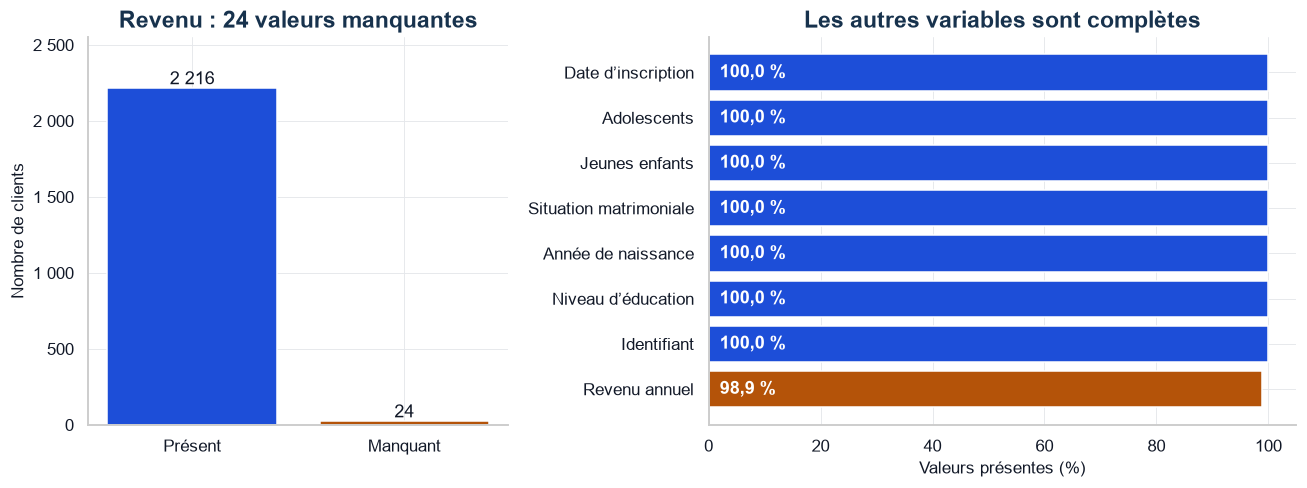

In [5]:
# Vue compacte de la qualité des données : aucune suppression n'a encore eu lieu.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].bar(["Présent", "Manquant"], [data["Income"].notna().sum(), data["Income"].isna().sum()], color=[pal[0], pal[2]])
for barre in axes[0].patches:
    axes[0].annotate(f"{int(barre.get_height()):,}".replace(",", " "),
                     (barre.get_x() + barre.get_width()/2, barre.get_height()), ha="center", va="bottom")
axes[0].set_title("Revenu : 24 valeurs manquantes")
axes[0].set_ylabel("Nombre de clients")
axes[0].set_ylim(0, len(data)*1.14)
completude = data.notna().mean().mul(100).sort_values().head(8)
axes[1].barh([LIBELLES.get(v, v) for v in completude.index], completude, color=[pal[2]] + [pal[0]]*7)
axes[1].set_xlim(0, 105)
axes[1].set_xlabel("Valeurs présentes (%)")
axes[1].set_title("Les autres variables sont complètes")
for i, valeur in enumerate(completude):
    axes[1].text(2, i, nombre(valeur, 1) + " %", color="white", va="center", fontweight="bold")
fig.tight_layout()
franciser(fig)
plt.show()

**Décision de nettoyage.** Seule `Income` comporte des valeurs manquantes : **24 clients**, soit **1,1 %** du fichier. Ces lignes sont écartées dans cette version. Une proportion faible ne garantit pas l’absence de biais ; une comparaison avec une imputation reste à mener.

`Dt_Customer` sera convertie en date. Les deux variables catégorielles conservées seront encodées avant l’ACP.

In [6]:
# Suppression des lignes sans revenu renseigné
data = data.dropna()
print("Nombre de lignes après suppression des valeurs manquantes :", nombre(len(data), 0))

Nombre de lignes après suppression des valeurs manquantes : 2 216


**Ancienneté relative du client.** `Customer_For` est la différence entre la date d’inscription la plus récente du fichier et la date d’inscription du client. Elle ne correspond pas à une ancienneté calculée à la date d’aujourd’hui.

In [7]:
# Conversion en datetime (format jour-mois-année)
data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"], dayfirst=True)

print("Date d'enregistrement la plus récente :", data["Dt_Customer"].max().strftime("%d/%m/%Y"))
print("Date d'enregistrement la plus ancienne :", data["Dt_Customer"].min().strftime("%d/%m/%Y"))

Date d'enregistrement la plus récente : 29/06/2014
Date d'enregistrement la plus ancienne : 30/07/2012


In [8]:
# Création de la variable "Customer_For" : ancienneté du client en jours,
# mesurée par rapport à la date d'enregistrement la plus récente
data["Customer_For"] = (data["Dt_Customer"].max() - data["Dt_Customer"]).dt.days

**Variables catégorielles.** Examiner les effectifs permet de documenter les regroupements de modalités.

In [9]:
for variable in ["Marital_Status", "Education"]:
    print(variable)
    display(tableau(data[variable].value_counts().rename("Effectif").to_frame(), precision=0))

Marital_Status


,Effectif
Marital_Status,
Married,857
Together,573
Single,471
Divorced,232
Widow,76
Alone,3
Absurd,2
YOLO,2


Education


,Effectif
Education,
Graduation,1 116
PhD,481
Master,365
2n Cycle,200
Basic,54


**Sept variables dérivées** : `Customer_For`, `Age` (en 2014), `Spent` (somme des six catégories de dépenses), `Living_With`, `Children`, `Family_Size` et `Is_Parent`.

L’éducation est regroupée en trois catégories. Les identifiants, dates sources, constantes et variables remplacées sont retirés. Plusieurs variables dérivées restent liées aux variables sources : cette redondance sera discutée dans les limites.

In [10]:
# Ingénierie des variables

# Âge du client en 2014, fin de la période d'observation
ANNEE_REFERENCE = 2014
data["Age"] = ANNEE_REFERENCE - data["Year_Birth"]

# Dépense totale du client sur toutes les catégories de produits
data["Spent"] = (
    data["MntWines"]
    + data["MntFruits"]
    + data["MntMeatProducts"]
    + data["MntFishProducts"]
    + data["MntSweetProducts"]
    + data["MntGoldProds"]
)

# Situation de cohabitation dérivée du statut matrimonial
data["Living_With"] = data["Marital_Status"].replace({
    "Married": "Partner",
    "Together": "Partner",
    "Absurd": "Alone",
    "Widow": "Alone",
    "YOLO": "Alone",
    "Divorced": "Alone",
    "Single": "Alone",
})

# Nombre total d'enfants dans le foyer (enfants + adolescents)
data["Children"] = data["Kidhome"] + data["Teenhome"]

# Taille du foyer (adultes + enfants)
data["Family_Size"] = data["Living_With"].map({"Alone": 1, "Partner": 2}) + data["Children"]

# Statut parental (1 = parent, 0 = non parent)
data["Is_Parent"] = np.where(data["Children"] > 0, 1, 0)

# Regroupement des niveaux d'éducation en 3 catégories
data["Education"] = data["Education"].replace({
    "Basic": "Undergraduate",
    "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate",
    "PhD": "Postgraduate",
})

# Renommage des colonnes de dépenses pour plus de clarté
data = data.rename(columns={
    "MntWines": "Wines",
    "MntFruits": "Fruits",
    "MntMeatProducts": "Meat",
    "MntFishProducts": "Fish",
    "MntSweetProducts": "Sweets",
    "MntGoldProds": "Gold",
})

# Suppression des variables devenues redondantes ou inutiles
# (Z_CostContact et Z_Revenue sont constantes)
to_drop = ["Marital_Status", "Dt_Customer", "Z_CostContact", "Z_Revenue", "Year_Birth", "ID"]
data = data.drop(to_drop, axis=1)

**Statistiques après création des variables.** Les maxima permettent notamment de repérer des âges et revenus atypiques.

In [11]:
display(tableau(decrire(data)))

,Libellé,Effectif,Moyenne,Écart-type,Minimum,1er quartile,Médiane,3e quartile,Maximum
Income,Revenu annuel,"2 216,00","52 247,25","25 173,08","1 730,00","35 303,00","51 381,50","68 522,00","666 666,00"
Kidhome,Jeunes enfants,"2 216,00","0,44","0,54","0,00","0,00","0,00","1,00","2,00"
Teenhome,Adolescents,"2 216,00","0,51","0,54","0,00","0,00","0,00","1,00","2,00"
Recency,Jours depuis le dernier achat,"2 216,00","49,01","28,95","0,00","24,00","49,00","74,00","99,00"
Wines,Dépenses en vin,"2 216,00","305,09","337,33","0,00","24,00","174,50","505,00","1 493,00"
Fruits,Dépenses en fruits,"2 216,00","26,36","39,79","0,00","2,00","8,00","33,00","199,00"
Meat,Dépenses en viande,"2 216,00","167,00","224,28","0,00","16,00","68,00","232,25","1 725,00"
Fish,Dépenses en poisson,"2 216,00","37,64","54,75","0,00","3,00","12,00","50,00","259,00"
Sweets,Dépenses en sucreries,"2 216,00","27,03","41,07","0,00","1,00","8,00","33,00","262,00"
Gold,Dépenses en produits en or,"2 216,00","43,97","51,82","0,00","9,00","24,50","56,00","321,00"


Le revenu maximal est de **666 666** et l’âge maximal de **121 ans**. Ces observations justifient un examen de la qualité des saisies. La sélection ci-dessous montre aussi les relations entre revenu, dépenses, âge et ancienneté.

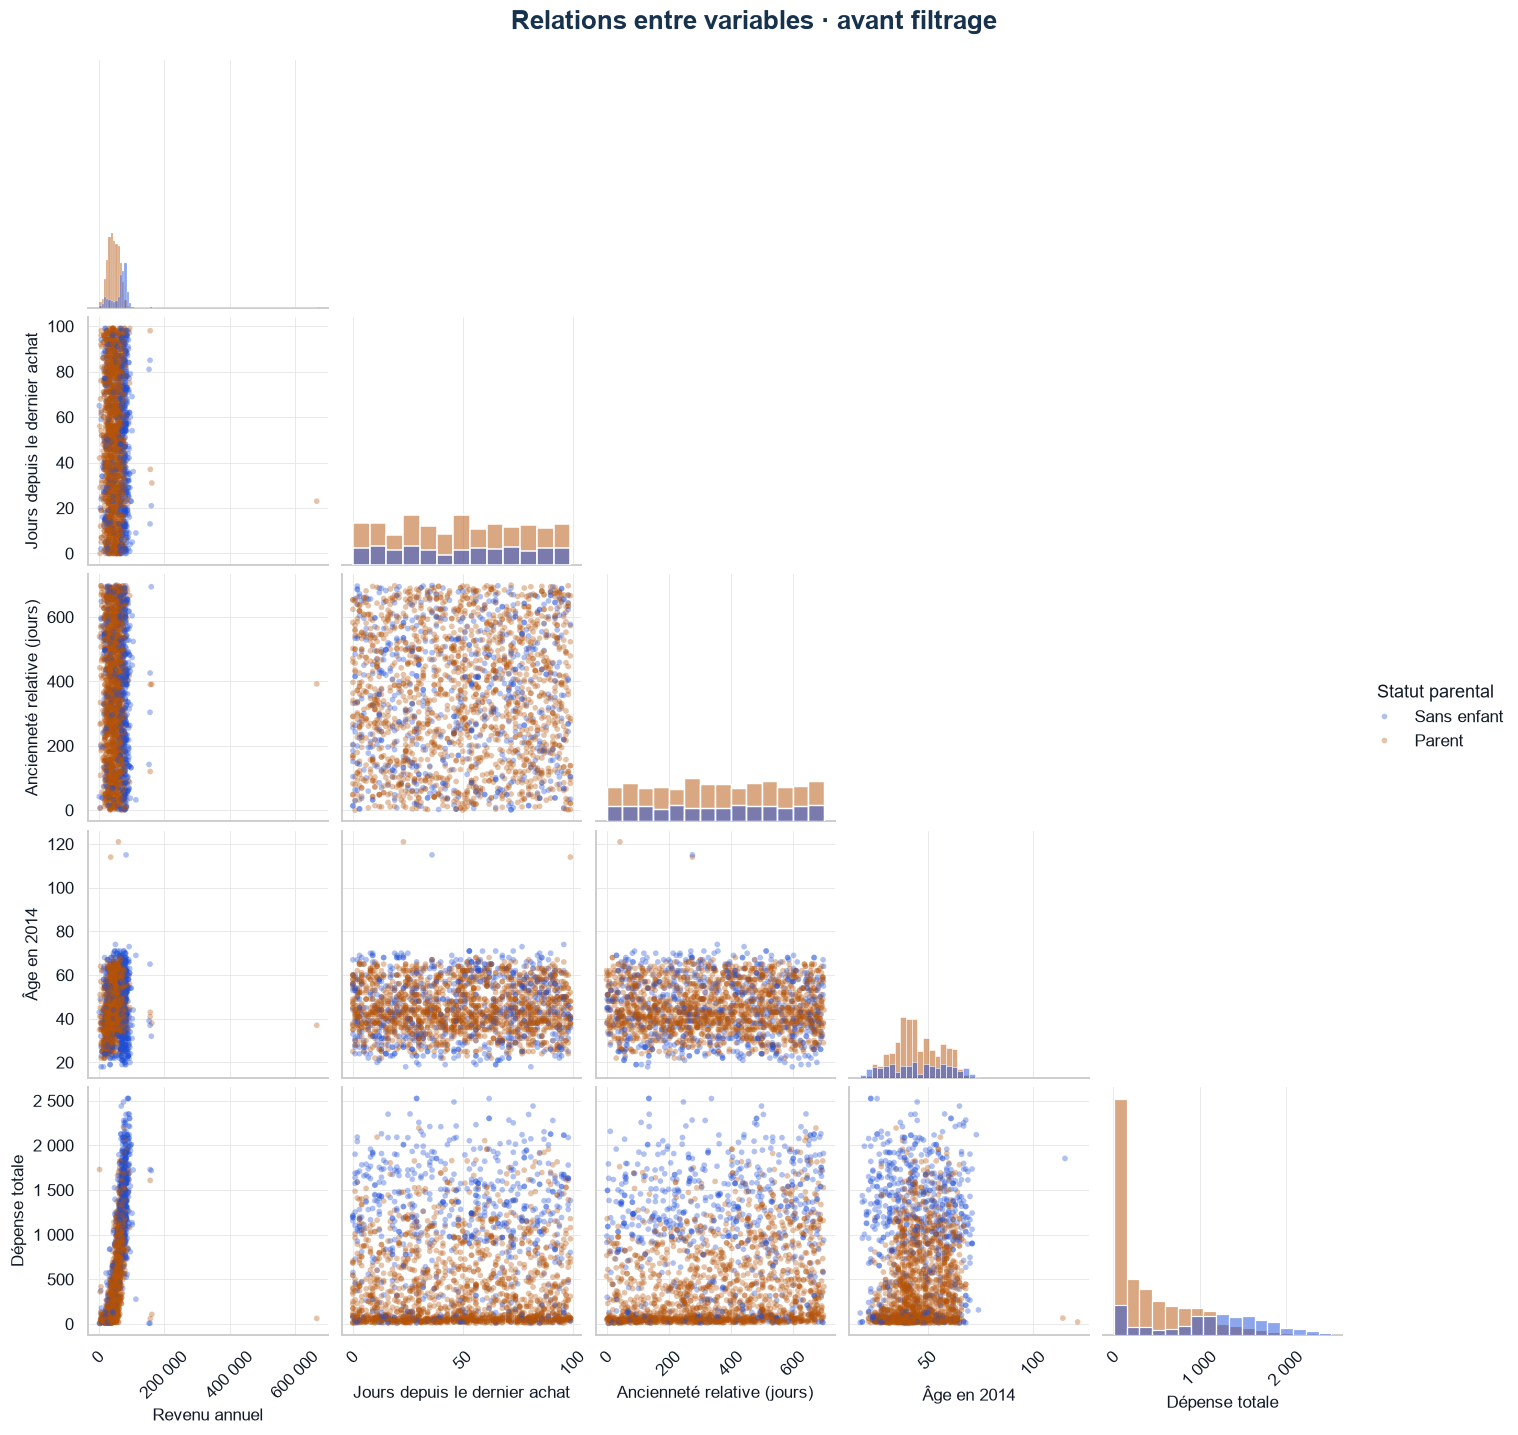

In [12]:
# Vue exploratoire avant le retrait des valeurs atypiques.
To_Plot = ["Income", "Recency", "Customer_For", "Age", "Spent", "Is_Parent"]
apercu = data[To_Plot].rename(columns=LIBELLES)
apercu[LIBELLES["Is_Parent"]] = apercu[LIBELLES["Is_Parent"]].map({0: "Sans enfant", 1: "Parent"})
g = sns.pairplot(apercu, hue=LIBELLES["Is_Parent"], hue_order=["Sans enfant", "Parent"], palette=[pal[0], pal[2]],
                 corner=True, diag_kind="hist", plot_kws={"alpha": 0.35, "s": 14, "edgecolor": "none"})
g.figure.suptitle("Relations entre variables · avant filtrage", fontsize=17, color=ENCRE, fontweight="bold", y=1.02)
franciser(g.figure)
for ax in g.axes.flat:
    if ax is not None:
        ax.tick_params(axis="x", labelrotation=45)
plt.show()

**Filtrage documenté.** Les clients d’au moins 90 ans et les revenus d’au moins 600 000 sont retirés : **4 lignes**, après les 24 revenus manquants. Ces seuils sont des choix de nettoyage, dont la sensibilité n’est pas testée ici.

In [13]:
# Suppression des valeurs aberrantes à l'aide de seuils sur l'âge et le revenu

# Clients de 90 ans ou plus (années de naissance invraisemblables)
data = data[data["Age"] < 90]

# Revenu supérieur à 600 000
data = data[data["Income"] < 600000]

print("Nombre d'observations après suppression des valeurs aberrantes :", nombre(len(data), 0))

Nombre d'observations après suppression des valeurs aberrantes : 2 212


**Dépendances entre variables.** La carte ci-dessous concerne les variables numériques, avant l’encodage des catégories.

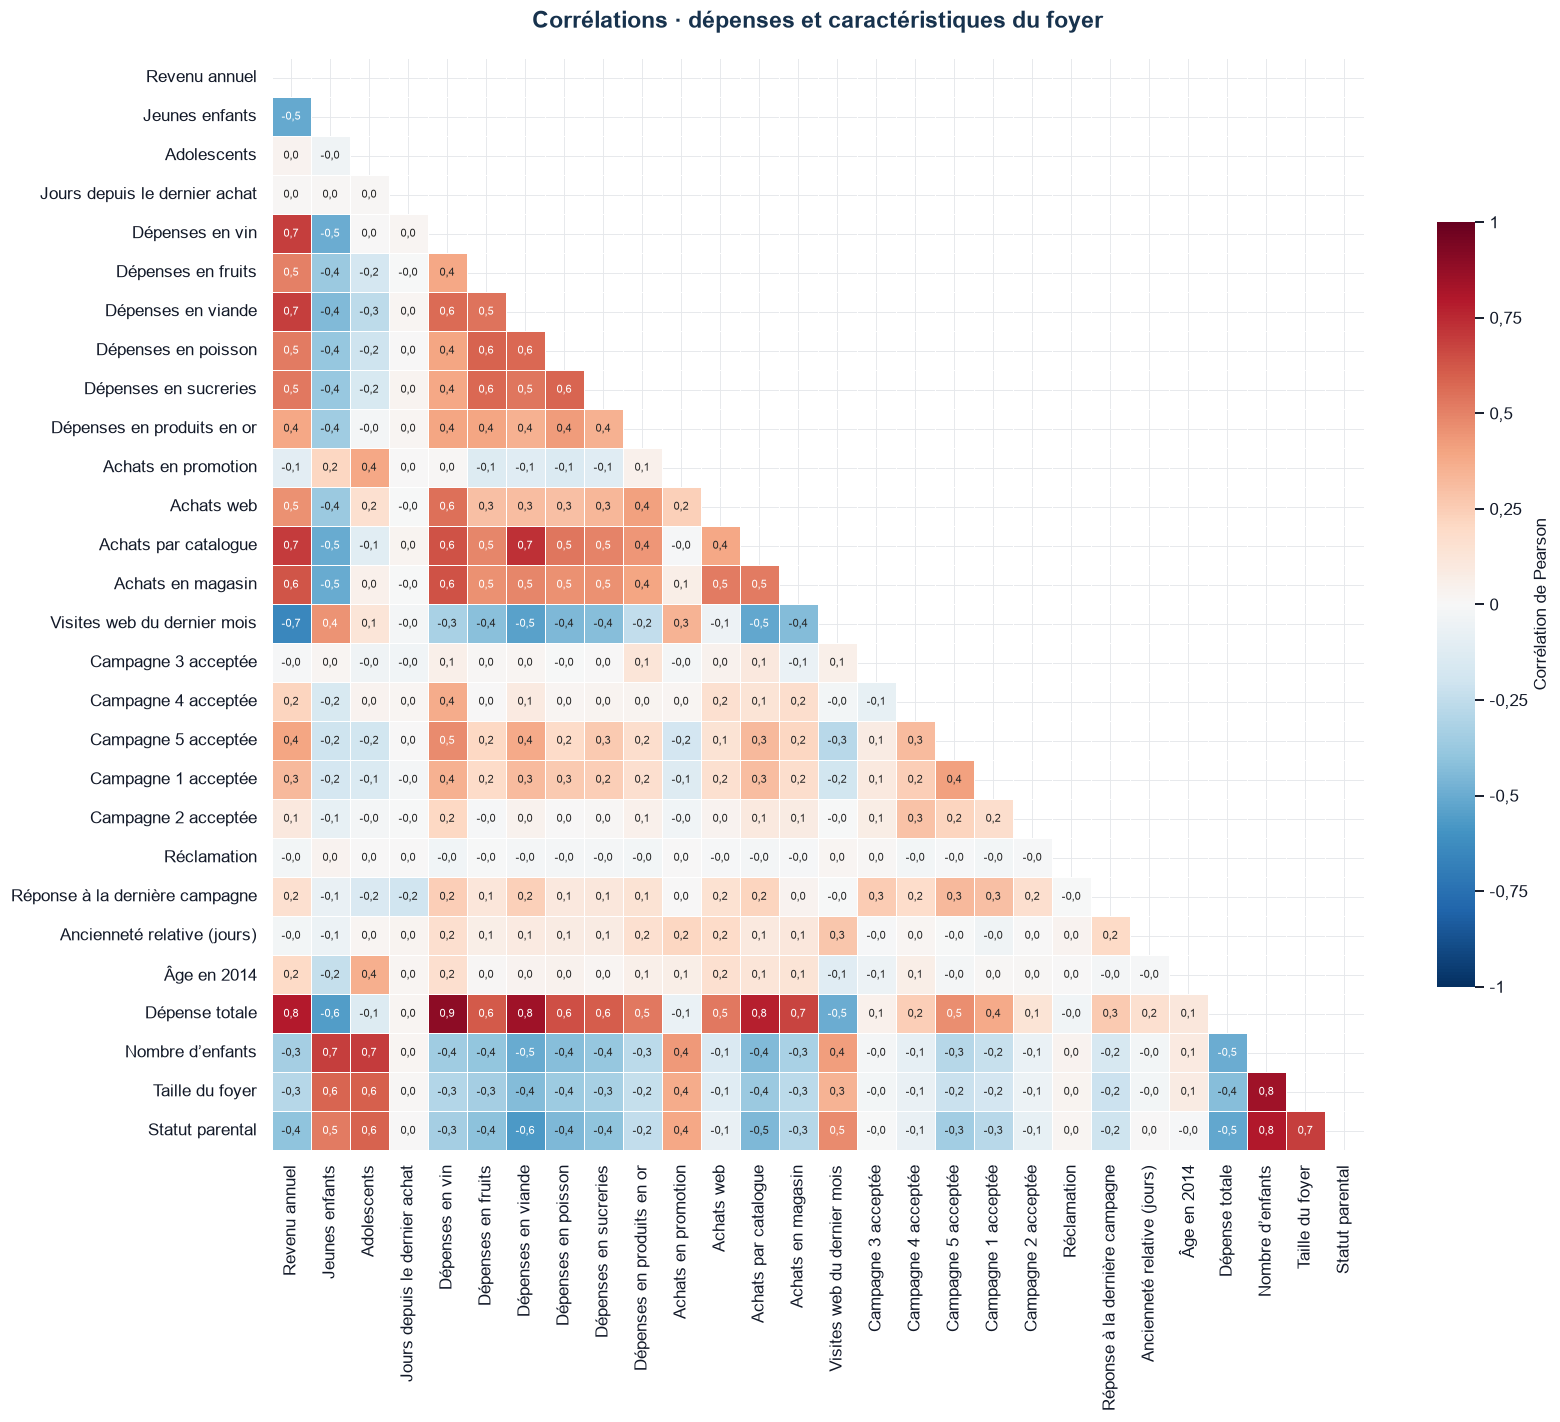

In [14]:
corrmat = data.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(16, 13))
corr_fr = corrmat.rename(index=LIBELLES, columns=LIBELLES)
sns.heatmap(corr_fr, mask=np.triu(np.ones_like(corr_fr, dtype=bool)), annot=corr_fr.map(lambda v: nombre(v, 1)), fmt="",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            annot_kws={"fontsize": 7}, cbar_kws={"shrink": 0.7, "label": "Corrélation de Pearson"}, ax=ax)
ax.set_title("Corrélations · dépenses et caractéristiques du foyer", pad=20)
plt.tight_layout()
franciser(fig)
plt.show()

**Lecture.** Les dépenses par produit sont corrélées entre elles et avec leur somme `Spent`. Le revenu est associé aux dépenses ; les caractéristiques du foyer sont également liées entre elles. Ces associations décrivent le fichier et ne démontrent pas de causalité.

L’ACP réduit la dimension de cette représentation. Elle n’annule pas le poids supplémentaire donné à un thème représenté par plusieurs variables redondantes.

<a id="4"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">04 · Prétraitement et choix de représentation</h2>

Les catégories sont encodées, puis les variables retenues sont standardisées.

**Limite conservée.** `LabelEncoder` code l’éducation par ordre alphabétique : Graduate = 0, Postgraduate = 1, Undergraduate = 2. Ces distances ne reflètent pas une progression scolaire. Un encodage adapté est une piste d’amélioration du modèle.

In [15]:
# Liste des variables catégorielles
object_cols = [col for col in data.columns if not pd.api.types.is_numeric_dtype(data[col])]

print("Variables catégorielles :", ", ".join(f"{c} ({LIBELLES[c]})" for c in object_cols))

Variables catégorielles : Education (Niveau d’éducation), Living_With (Situation de vie)


In [16]:
# Encodage des variables catégorielles avec LabelEncoder
LE = LabelEncoder()
for col in object_cols:
    data[col] = LE.fit_transform(data[col])

print("Toutes les variables sont désormais numériques.")

Toutes les variables sont désormais numériques.


**Séparation des rôles.** `AcceptedCmp1` à `AcceptedCmp5`, `Response` et `Complain` sont exclus du clustering et servent au profilage après construction des groupes.

`NumDealsPurchases` et les canaux d’achat restent inclus. Leurs différences entre clusters ne constituent donc pas une validation indépendante. La standardisation donne une échelle comparable aux variables ; elle ne corrige pas leurs redondances.

In [17]:
# Copie du jeu de données
ds = data.copy()

# Retrait des variables liées aux campagnes marketing, plaintes et réponses
cols_del = ["AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "AcceptedCmp1", "AcceptedCmp2", "Complain", "Response"]
ds = ds.drop(cols_del, axis=1)

# Standardisation
scaler = StandardScaler()
scaled_ds = pd.DataFrame(scaler.fit_transform(ds), columns=ds.columns)

print("Toutes les variables ont été mises à l'échelle.")

Toutes les variables ont été mises à l'échelle.


In [18]:
print("Aperçu des 23 variables standardisées")
display(tableau(scaled_ds.head()))

Aperçu des 23 variables standardisées


,Education,Income,Kidhome,Teenhome,Recency,Wines,Fruits,Meat,Fish,Sweets,Gold,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Customer_For,Age,Spent,Living_With,Children,Family_Size,Is_Parent
0,"-0,89","0,29","-0,82","-0,93","0,31","0,98","1,55","1,69","2,45","1,48","0,85","0,35","1,43","2,50","-0,56","0,69","1,53","1,02","1,68","-1,35","-1,26","-1,76","-1,58"
1,"-0,89","-0,26","1,04","0,91","-0,38","-0,87","-0,64","-0,72","-0,65","-0,63","-0,73","-0,17","-1,13","-0,57","-1,17","-0,13","-1,19","1,27","-0,96","-1,35","1,40","0,45","0,63"
2,"-0,89","0,91","-0,82","-0,93","-0,80","0,36","0,57","-0,18","1,34","-0,15","-0,04","-0,69","1,43","-0,23","1,29","-0,54","-0,21","0,33","0,28","0,74","-1,26","-0,65","-1,58"
3,"-0,89","-1,18","1,04","-0,93","-0,80","-0,87","-0,56","-0,66","-0,50","-0,59","-0,75","-0,17","-0,76","-0,91","-0,56","0,28","-1,06","-1,29","-0,92","0,74","0,07","0,45","0,63"
4,"0,57","0,29","1,04","-0,93","1,55","-0,39","0,42","-0,22","0,15","-0,00","-0,56","1,39","0,33","0,11","0,06","-0,13","-0,95","-1,03","-0,31","0,74","0,07","0,45","0,63"


La représentation standardisée est utilisée pour l’ACP. On mesure explicitement l’information conservée par les axes retenus.

<a id="5"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">05 · ACP et projection interactive</h2>

L’ACP produit des axes non corrélés résumant les variables standardisées. Les graphiques documentent le compromis entre dimension réduite et variance conservée.

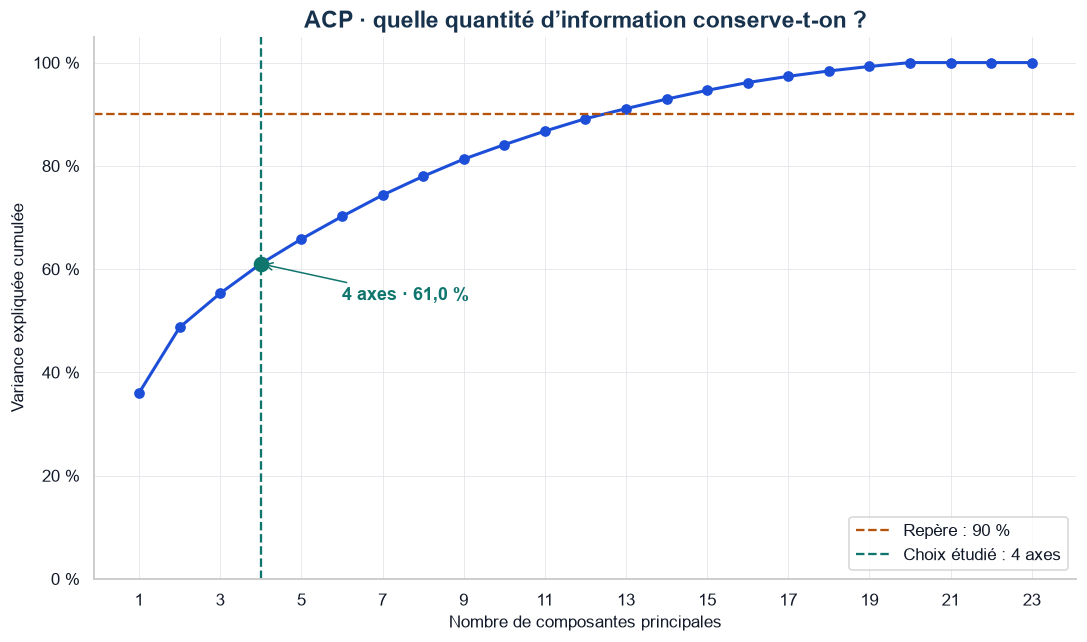

3 axes : 55,30 % · 4 axes : 61,03 %


In [19]:
pca_full = PCA()
pca_full.fit(scaled_ds)
cumulative_variance_full = np.cumsum(pca_full.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(1, len(cumulative_variance_full)+1), cumulative_variance_full, marker="o", color=pal[0], linewidth=2)
ax.axhline(0.90, color=pal[2], linestyle="--", label="Repère : 90 %")
ax.axvline(4, color=pal[1], linestyle="--", label="Choix étudié : 4 axes")
ax.scatter([4], [cumulative_variance_full[3]], color=pal[1], s=85, zorder=4)
ax.annotate(f"4 axes · {pourcentage(cumulative_variance_full[3])}", (4, cumulative_variance_full[3]),
            xytext=(6, 0.54), arrowprops=dict(arrowstyle="->", color=pal[1]), color=pal[1], fontweight="bold")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set(ylim=(0, 1.05), xlabel="Nombre de composantes principales", ylabel="Variance expliquée cumulée",
       title="ACP · quelle quantité d’information conserve-t-on ?")
ax.set_xticks(range(1, len(cumulative_variance_full)+1, 2))
ax.legend(loc="lower right", frameon=True)
fig.tight_layout()
franciser(fig)
sauvegarder("00_variance_cumulee_acp.png")
plt.show()
print(f"3 axes : {pourcentage(cumulative_variance_full[2], 2)} · 4 axes : {pourcentage(cumulative_variance_full[3], 2)}")

**Quatre axes conservent 61,0 % de la variance.** Le seuil de 90 % est atteint à la 13ᵉ composante. Le choix de quatre axes réduit la dimension, mais écarte environ 39 % de la variance.

Il s’agit d’un choix de représentation à comparer à d’autres nombres de composantes. La perte de variance ne prouve pas que les axes écartés ne contiennent que du bruit. Les deux vues 3D montrent seulement les trois premiers axes, soit **55,3 %** de la variance ; le clustering utilise bien **quatre axes**.

In [20]:
pca = PCA(n_components=4)
PCA_ds = pd.DataFrame(pca.fit_transform(scaled_ds), columns=["axe1", "axe2", "axe3", "axe4"])
display(tableau(decrire(PCA_ds)))

,Libellé,Effectif,Moyenne,Écart-type,Minimum,1er quartile,Médiane,3e quartile,Maximum
axe1,Axe 1,"2 212,00","0,00","2,88","-5,98","-2,54","-0,78","2,39","7,45"
axe2,Axe 2,"2 212,00","0,00","1,71","-4,19","-1,32","-0,17","1,23","6,17"
axe3,Axe 3,"2 212,00","-0,00","1,23","-3,63","-0,85","-0,05","0,86","6,75"
axe4,Axe 4,"2 212,00","0,00","1,15","-3,13","-0,76","-0,01","0,89","3,40"


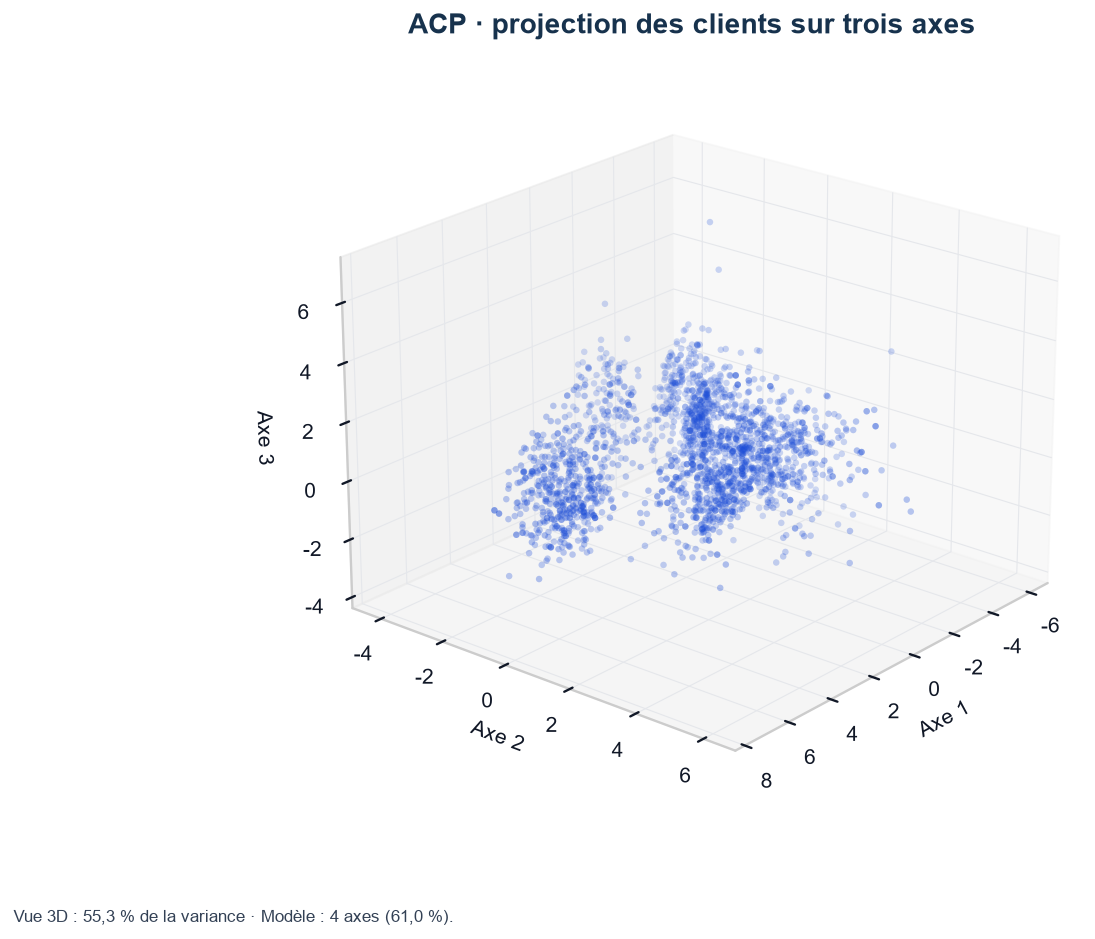

Vue interactive : reports/figures_interactives/projection_acp_3d.html


In [21]:
# Projection avant la construction des groupes.
x, y, z = PCA_ds["axe1"], PCA_ds["axe2"], PCA_ds["axe3"]
fig = plt.figure(figsize=(10, 7.5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x, y, z, c=pal[0], s=12, alpha=0.6, edgecolors="none")
ax.set(xlabel="Axe 1", ylabel="Axe 2", zlabel="Axe 3", title="ACP · projection des clients sur trois axes")
ax.view_init(elev=22, azim=40)
note_figure(fig, note_variance() + ".")
afficher_3d(graphique_3d(PCA_ds, "ACP · projection des clients"), fig, "projection_acp_3d.html")

***

<a id="6"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">06 · Construction des segments</h2>

Le clustering agglomératif utilise le critère de **Ward**, sur les quatre composantes principales.

Le coude KMeans est un repère exploratoire, associé à un autre algorithme. Le choix final est confronté aux indices internes du clustering agglomératif dans la section suivante.

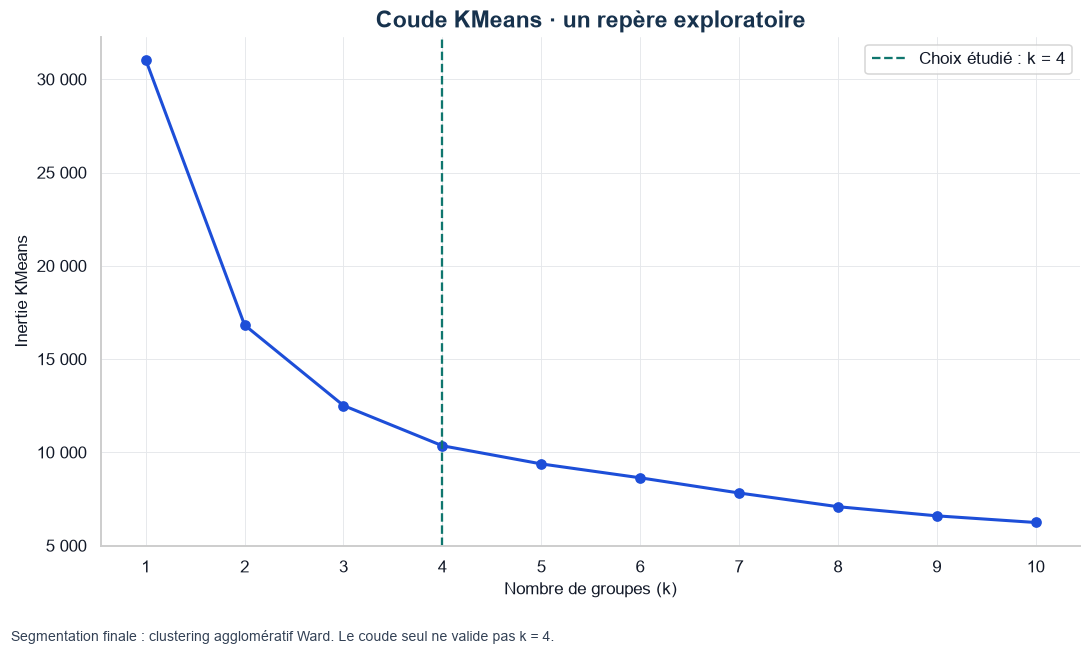

In [22]:
inertia = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(PCA_ds)
    inertia.append(kmeans.inertia_)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(k_range, inertia, "o-", color=pal[0], linewidth=2)
ax.axvline(4, color=pal[1], linestyle="--", label="Choix étudié : k = 4")
ax.set(xlabel="Nombre de groupes (k)", ylabel="Inertie KMeans", title="Coude KMeans · un repère exploratoire")
ax.set_xticks(list(k_range))
ax.legend()
note_figure(fig, "Segmentation finale : clustering agglomératif Ward. Le coude seul ne valide pas k = 4.")
fig.tight_layout(rect=(0, 0.05, 1, 1))
franciser(fig)
sauvegarder("01_methode_du_coude.png")
plt.show()

Le coude est peu marqué, autour de trois à quatre groupes. **Quatre segments sont étudiés** pour décrire des profils plus détaillés. Ce choix n’est pas présenté comme optimal : il faut également regarder la séparation statistique et vérifier ultérieurement la stabilité et l’utilité des groupes.

In [23]:
# Clustering agglomératif en 4 groupes (critère de Ward)
AC = AgglomerativeClustering(n_clusters=4, linkage="ward")
yhat_AC = AC.fit_predict(PCA_ds)
PCA_ds["Clusters"] = yhat_AC

# Ajout des clusters au jeu de données d'origine
data["Clusters"] = yhat_AC

**Explorer les groupes.** Faites tourner le nuage, zoomez et survolez les clients. La légende permet de masquer ou d’isoler un cluster. L’aperçu statique conserve les couleurs et les axes de la vue interactive.

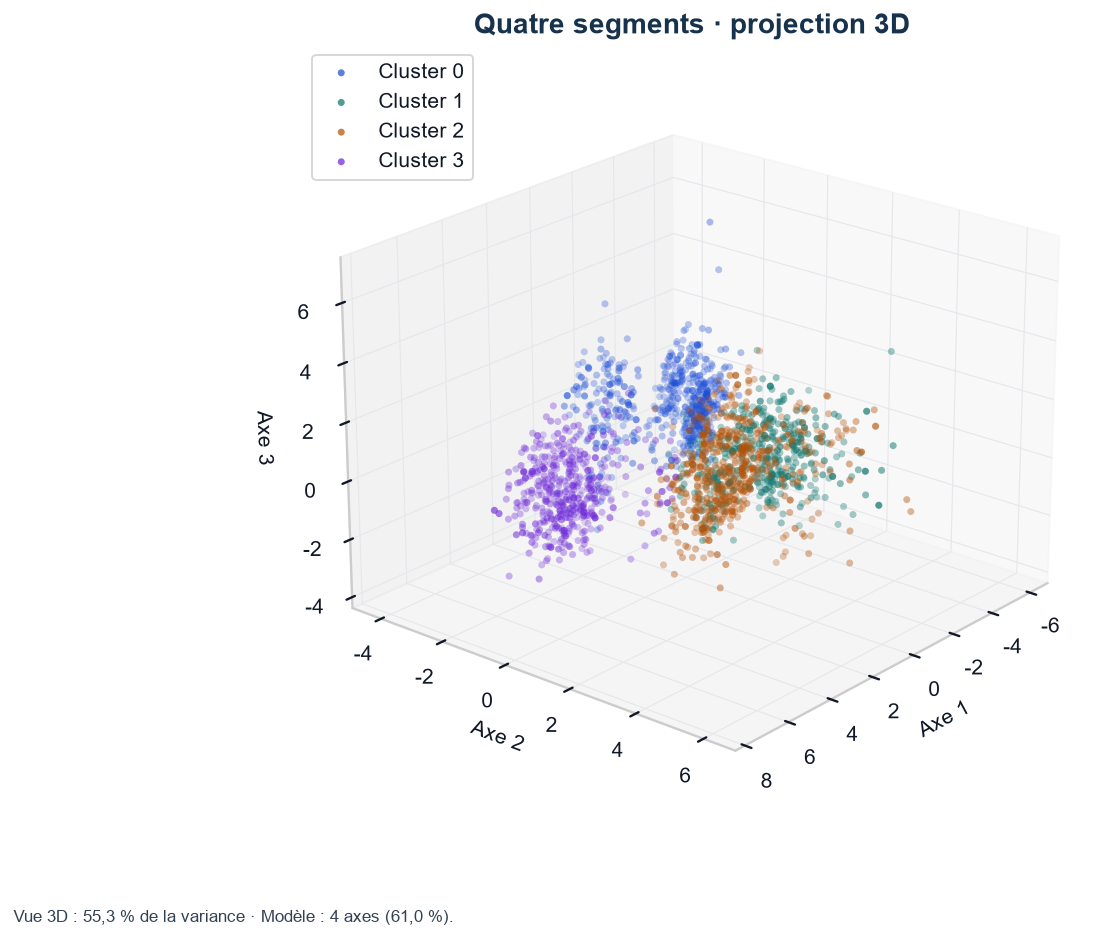

Vue interactive : reports/figures_interactives/clusters_3d.html


In [24]:
fig = plt.figure(figsize=(10, 7.5))
ax = fig.add_subplot(111, projection="3d")
for groupe in range(4):
    masque = PCA_ds["Clusters"].eq(groupe)
    ax.scatter(x[masque], y[masque], z[masque], s=14, color=pal[groupe], alpha=0.72,
               edgecolors="none", label=f"Cluster {groupe}")
ax.set(xlabel="Axe 1", ylabel="Axe 2", zlabel="Axe 3", title="Quatre segments · projection 3D")
ax.view_init(elev=22, azim=40)
ax.legend(loc="upper left", frameon=True)
note_figure(fig, note_variance() + ".")
franciser(fig)
sauvegarder("02_clusters_3d.png")
afficher_3d(graphique_3d(PCA_ds, "Quatre segments · explorer les profils", groupes=True), fig, "clusters_3d.html")

La projection comporte des zones de recouvrement et dépend de l’angle de vue. Elle aide à explorer les groupes ; les indices calculés sur les quatre axes apportent une mesure complémentaire de leur séparation.

<a id="7"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">07 · Évaluation, robustesse et comportements d’achat</h2>

La silhouette est meilleure quand elle augmente ; Davies-Bouldin est meilleur quand il diminue. Ces mesures internes évaluent la géométrie des groupes, sans démontrer leur rentabilité commerciale.

In [25]:
# Indices de qualité de la segmentation retenue
X_pca = PCA_ds.drop(columns="Clusters")
print(f"Coefficient de silhouette (k = 4) : {nombre(silhouette_score(X_pca, yhat_AC), 3)}")
print(f"Indice de Davies-Bouldin (k = 4) : {nombre(davies_bouldin_score(X_pca, yhat_AC), 3)}")

# Comparaison avec d'autres nombres de clusters
scores = []
for k in range(2, 9):
    labels_k = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_pca)
    scores.append({
        "Groupes (k)": k,
        "Silhouette": silhouette_score(X_pca, labels_k),
        "Davies-Bouldin": davies_bouldin_score(X_pca, labels_k),
    })
display(tableau(pd.DataFrame(scores).set_index("Groupes (k)"), precision=3))

Coefficient de silhouette (k = 4) : 0,304
Indice de Davies-Bouldin (k = 4) : 1,188


,Silhouette,Davies-Bouldin
Groupes (k),,
2,"0,390","0,885"
3,"0,336","1,141"
4,"0,304","1,188"
5,"0,276","1,116"
6,"0,240","1,254"
7,"0,256","1,284"
8,"0,266","1,309"


**Séparation modérée.** Pour quatre groupes, silhouette = **0,304** et Davies-Bouldin = **1,188**. Deux groupes obtiennent de meilleurs indices (0,390 et 0,885), tout comme trois groupes (0,336 et 1,141).

Le découpage en quatre segments offre davantage de détail descriptif. Son avantage commercial n’est pas démontré par ces indices et doit être validé séparément.

**Robustesse des segments.** Quatre choix de préparation sont testés en réestimant toute la chaîne (standardisation, ACP à quatre axes, Ward à quatre groupes) :

- **Encodage de l’éducation** : `LabelEncoder` suit l’ordre alphabétique. On recode l’éducation dans l’ordre des diplômes.
- **Asymétrie des montants** : le revenu et les dépenses ont de longues queues à droite. On les transforme par `log1p`.
- **Redondance** : `Spent`, `Children`, `Family_Size` et `Is_Parent` répètent des informations déjà présentes. On les retire.
- **Stabilité** : on réestime les segments sur 100 sous-échantillons tirés au hasard, chacun avec 80 % des clients.

L’**indice de Rand ajusté** compare deux partitions des mêmes clients, quels que soient les numéros des groupes : 1 signifie une concordance parfaite et 0 une concordance due au hasard. La part de clients conservés compte ceux qui restent dans le groupe correspondant le mieux à leur segment d’origine.

In [26]:
def segmenter(variables):
    """Même chaîne que le modèle : standardisation, ACP à 4 axes, Ward à 4 groupes."""
    axes_acp = PCA(n_components=4).fit_transform(StandardScaler().fit_transform(variables))
    return AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(axes_acp), axes_acp

def comparer(variante, libelle):
    """Concordance d'une variante avec le modèle retenu, sur les mêmes clients."""
    labels, axes_variante = segmenter(variante)
    correspondance = pd.crosstab(yhat_AC, labels)
    return {"Test": libelle, "Indice de Rand ajusté": adjusted_rand_score(yhat_AC, labels),
            "Clients conservés (%)": 100 * correspondance.max(axis=1).sum() / len(variante),
            "Silhouette": silhouette_score(axes_variante, labels)}

# Variante 1 : éducation codée dans l'ordre des diplômes (Undergraduate < Graduate < Postgraduate).
# LabelEncoder avait produit Graduate = 0, Postgraduate = 1, Undergraduate = 2.
ds_ordonne = ds.copy()
ds_ordonne["Education"] = ds_ordonne["Education"].map({2: 0, 0: 1, 1: 2})

# Variante 2 : revenu et dépenses transformés par log1p pour réduire le poids des valeurs extrêmes.
montants = ["Income", "Wines", "Fruits", "Meat", "Fish", "Sweets", "Gold", "Spent"]
ds_log = ds.copy()
ds_log[montants] = np.log1p(ds_log[montants])

# Variante 3 : retrait des variables dérivées qui répètent les dépenses et la composition du foyer.
ds_sans_redondance = ds.drop(columns=["Spent", "Children", "Family_Size", "Is_Parent"])

resultats = [comparer(ds_ordonne, "Éducation codée dans l'ordre des diplômes"),
             comparer(ds_log, "Revenu et dépenses en log1p"),
             comparer(ds_sans_redondance, "Sans variables dérivées redondantes")]

# Stabilité : chaîne complète réestimée sur 100 sous-échantillons de 80 % des clients.
rng = np.random.default_rng(42)
ari_stabilite = []
for _ in range(100):
    lignes = np.sort(rng.choice(len(ds), size=int(0.8 * len(ds)), replace=False))
    labels_sous, _ = segmenter(ds.iloc[lignes])
    ari_stabilite.append(adjusted_rand_score(yhat_AC[lignes], labels_sous))
ari_stabilite = np.array(ari_stabilite)
for libelle, valeur in [("Sous-échantillons de 80 % : médiane", np.median(ari_stabilite)),
                        ("Sous-échantillons de 80 % : 5e centile", np.percentile(ari_stabilite, 5)),
                        ("Sous-échantillons de 80 % : minimum", ari_stabilite.min())]:
    resultats.append({"Test": libelle, "Indice de Rand ajusté": valeur})

display(tableau(pd.DataFrame(resultats).set_index("Test"), precision=3, precisions={"Clients conservés (%)": 1}))

,Indice de Rand ajusté,Clients conservés (%),Silhouette
Test,,,
Éducation codée dans l'ordre des diplômes,"0,806","92,3","0,280"
Revenu et dépenses en log1p,"0,763","90,3","0,311"
Sans variables dérivées redondantes,"0,531","78,3","0,238"
Sous-échantillons de 80 % : médiane,"0,806",-,-
Sous-échantillons de 80 % : 5e centile,"0,671",-,-
Sous-échantillons de 80 % : minimum,"0,537",-,-


**Lecture des tests.** Deux choix de préparation modifient peu les segments : l’éducation codée dans l’ordre des diplômes conserve **92,3 %** des clients (indice de Rand ajusté **0,81**) et la transformation `log1p` des montants en conserve **90,3 %** (**0,76**).

La **redondance** pèse davantage : sans les quatre variables dérivées, **78,3 %** des clients restent dans le segment correspondant (indice **0,53**) et la silhouette baisse à **0,238**. Les segments dépendent donc en partie du poids donné aux dépenses et à la composition du foyer par le choix des variables.

Sur les 100 sous-échantillons, la concordance médiane est de **0,81**, mais 5 % des tirages descendent sous **0,67** (minimum 0,54). Les profils principaux se retrouvent, avec des frontières qui varient selon les clients inclus : les segments sont des repères descriptifs, pas des catégories figées. Le modèle retenu est conservé pour rester comparable aux résultats présentés.

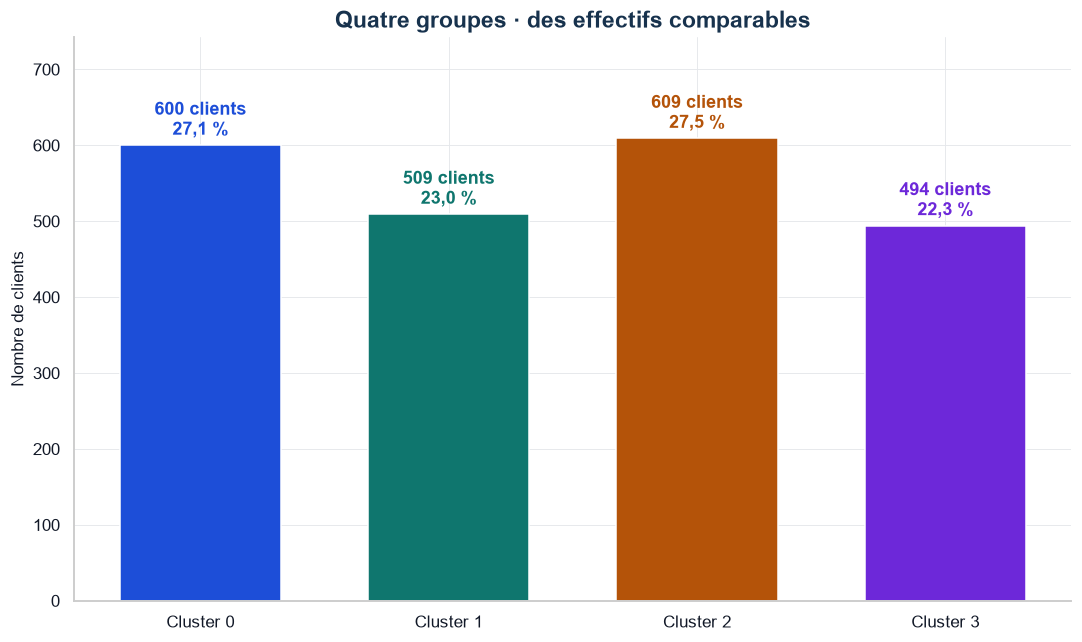

In [27]:
effectifs = data["Clusters"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar([f"Cluster {i}" for i in effectifs.index], effectifs, color=pal, width=0.65)
for i, n in enumerate(effectifs):
    ax.text(i, n+14, f"{n} clients\n{pourcentage(n/len(data))}", ha="center", fontweight="bold", color=pal[i])
ax.set(ylim=(0, effectifs.max()*1.22), ylabel="Nombre de clients", title="Quatre groupes · des effectifs comparables")
fig.tight_layout()
franciser(fig)
sauvegarder("03_repartition_clusters.png")
plt.show()

Les groupes rassemblent **600, 509, 609 et 494 clients**. Aucun n’est très petit dans cet échantillon. Leur taille ne suffit pas à démontrer leur accessibilité ni leur pertinence pour une action commerciale.

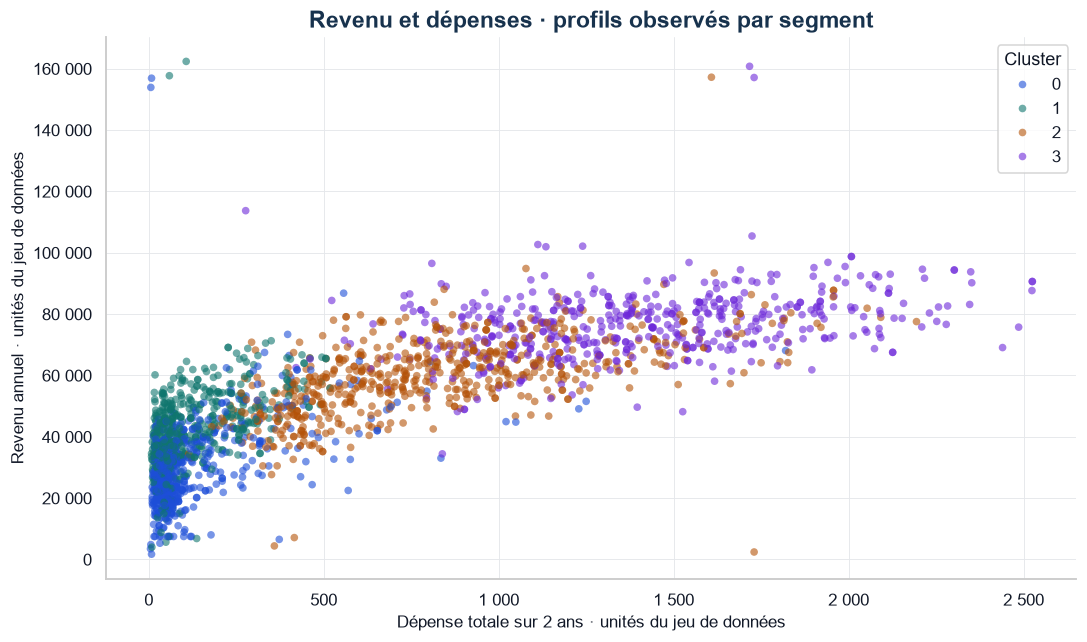

In [28]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=data, x="Spent", y="Income", hue="Clusters", palette=pal, s=25, alpha=0.6, linewidth=0, ax=ax)
ax.set(title="Revenu et dépenses · profils observés par segment",
       xlabel="Dépense totale sur 2 ans · unités du jeu de données",
       ylabel="Revenu annuel · unités du jeu de données")
ax.legend(title="Cluster", frameon=True)
fig.tight_layout()
franciser(fig)
sauvegarder("04_revenu_vs_depenses.png")
plt.show()

Les clusters 0 et 1 ont de faibles dépenses moyennes ; les clusters 2 et 3 présentent des dépenses plus élevées. Le revenu et les dépenses ont participé à la construction des groupes : cette figure décrit leur composition, sans constituer une validation externe.

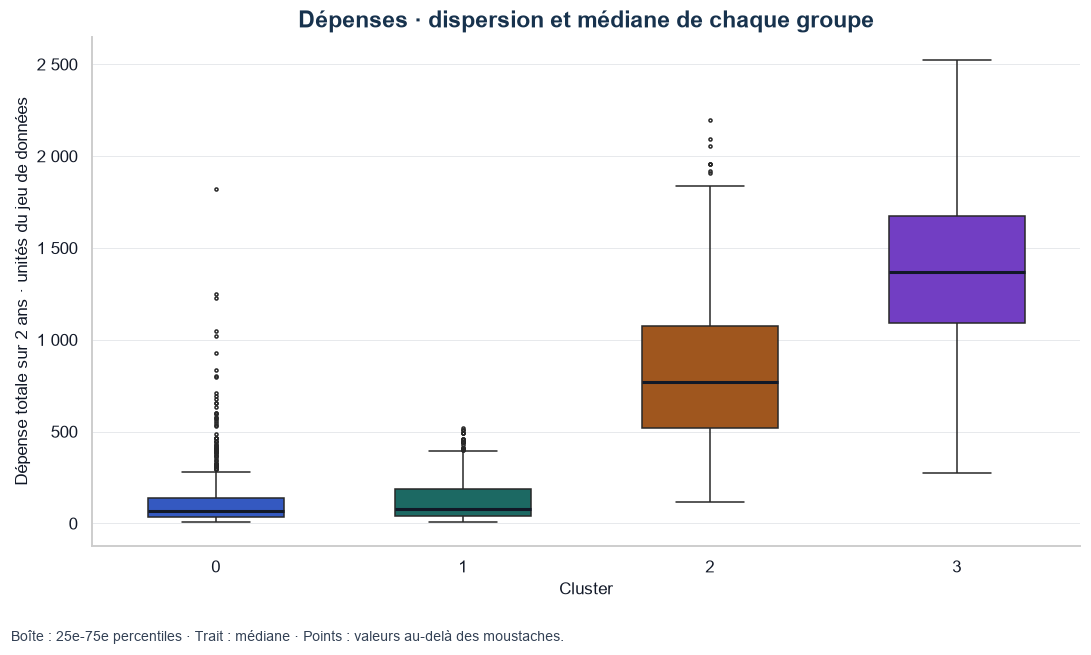

In [29]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=data, x="Clusters", y="Spent", hue="Clusters", palette=pal, legend=False,
            width=0.55, fliersize=2, medianprops={"color": "#111827", "linewidth": 2}, ax=ax)
ax.set(title="Dépenses · dispersion et médiane de chaque groupe", xlabel="Cluster",
       ylabel="Dépense totale sur 2 ans · unités du jeu de données")
note_figure(fig, "Boîte : 25e-75e percentiles · Trait : médiane · Points : valeurs au-delà des moustaches.")
fig.tight_layout(rect=(0, 0.05, 1, 1))
franciser(fig)
sauvegarder("05_distribution_depenses.png")
plt.show()

Les boîtes montrent les écarts de médiane et la dispersion interne. Les moyennes seules ne résument pas toute la diversité des clients à l’intérieur d’un segment.

**Réponses observées aux campagnes.** Les variables d’acceptation ont été exclues de la construction des groupes. Leur comparaison fournit un descriptif complémentaire.

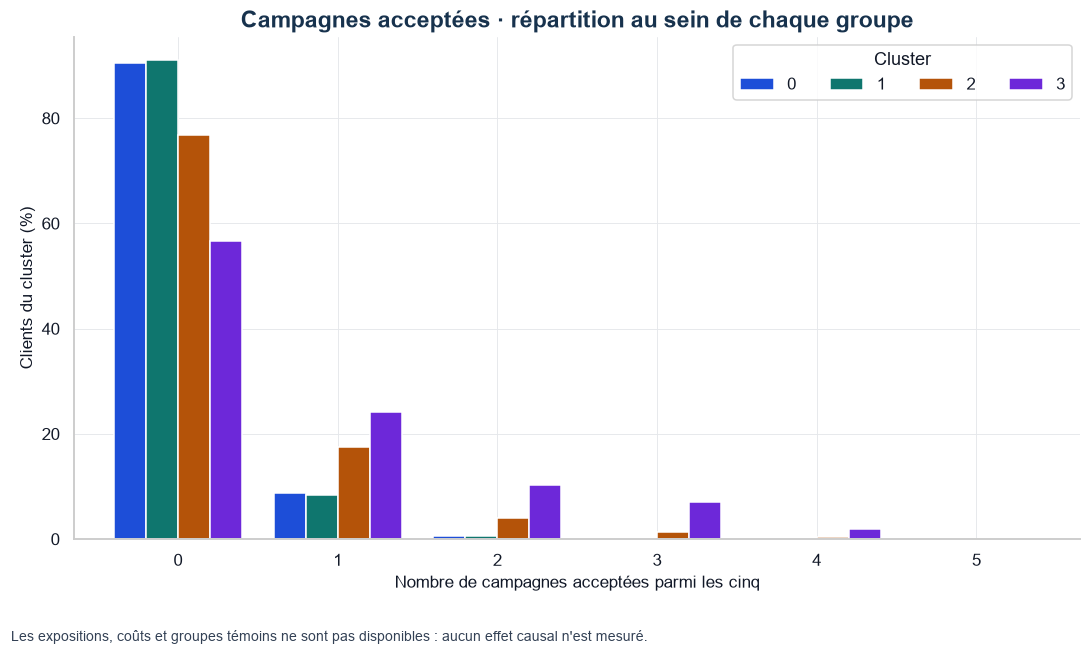

Aucune des cinq campagnes acceptée : 79,3 %


,Campagnes acceptées (moyenne),Réponse à la dernière campagne (taux)
Segment,,
0,"0,10","0,12"
1,"0,10","0,06"
2,"0,31","0,12"
3,"0,73","0,31"


In [30]:
# Nombre total de campagnes acceptées par client
data["Total_Promos"] = (
    data["AcceptedCmp1"] + data["AcceptedCmp2"] + data["AcceptedCmp3"] + data["AcceptedCmp4"] + data["AcceptedCmp5"]
)


# Pourcentages à l'intérieur de chaque cluster, afin de comparer des groupes de tailles différentes.
acceptations = pd.crosstab(data["Total_Promos"], data["Clusters"], normalize="columns").mul(100)
acceptations = acceptations.reindex(range(6), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 6))
acceptations.plot.bar(ax=ax, color=pal, width=0.8)
ax.set(title="Campagnes acceptées · répartition au sein de chaque groupe",
       xlabel="Nombre de campagnes acceptées parmi les cinq", ylabel="Clients du cluster (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Cluster", ncol=4, loc="upper right")
note_figure(fig, "Les expositions, coûts et groupes témoins ne sont pas disponibles : aucun effet causal n'est mesuré.")
fig.tight_layout(rect=(0, 0.06, 1, 1))
franciser(fig)
sauvegarder("06_promos_par_cluster.png")
plt.show()
print(f"Aucune des cinq campagnes acceptée : {pourcentage((data['Total_Promos'] == 0).mean())}")
reponses = data.groupby("Clusters")[["Total_Promos", "Response"]].mean()
reponses.columns = ["Campagnes acceptées (moyenne)", "Réponse à la dernière campagne (taux)"]
reponses.index.name = "Segment"
display(tableau(reponses))

**79,3 % des clients** n’ont accepté aucune des cinq campagnes. Le cluster 3 a le nombre moyen d’acceptations le plus élevé et la plus forte proportion de réponses positives à la dernière campagne (**30,6 %**).

On ne connaît pas les expositions individuelles, les coûts ni un groupe témoin. Ces écarts ne permettent pas de conclure que les campagnes étaient mal ciblées ou qu’une nouvelle campagne sera efficace.

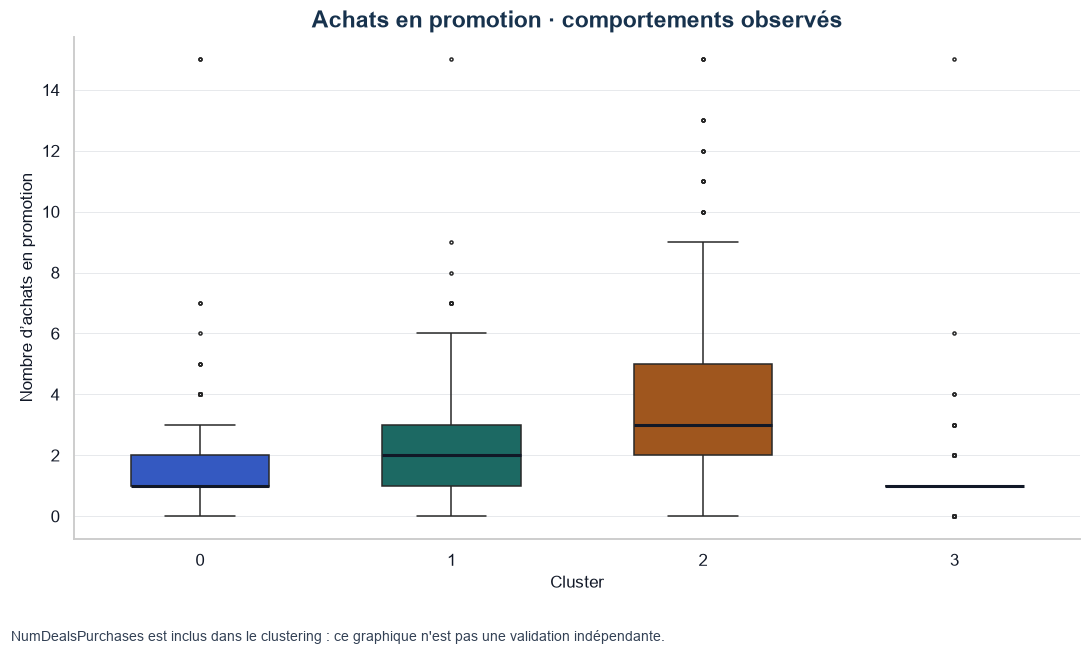

In [31]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=data, x="Clusters", y="NumDealsPurchases", hue="Clusters", palette=pal, legend=False,
            width=0.55, fliersize=2, medianprops={"color": "#111827", "linewidth": 2}, ax=ax)
ax.set(title="Achats en promotion · comportements observés", xlabel="Cluster", ylabel="Nombre d’achats en promotion")
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
note_figure(fig, "NumDealsPurchases est inclus dans le clustering : ce graphique n'est pas une validation indépendante.")
fig.tight_layout(rect=(0, 0.06, 1, 1))
franciser(fig)
sauvegarder("07_deals_par_cluster.png")
plt.show()

Le cluster 2 présente davantage d’achats en promotion (**3,7 en moyenne**) et le cluster 3 moins (**1,1**). Cette variable étant incluse dans le clustering, ces différences font partie de la description des groupes.

Elles ne mesurent ni la sensibilité causale au prix ni les achats qui auraient eu lieu sans remise. Une comparaison contrôlée d’offres avec et sans remise permettrait de tester ces hypothèses.

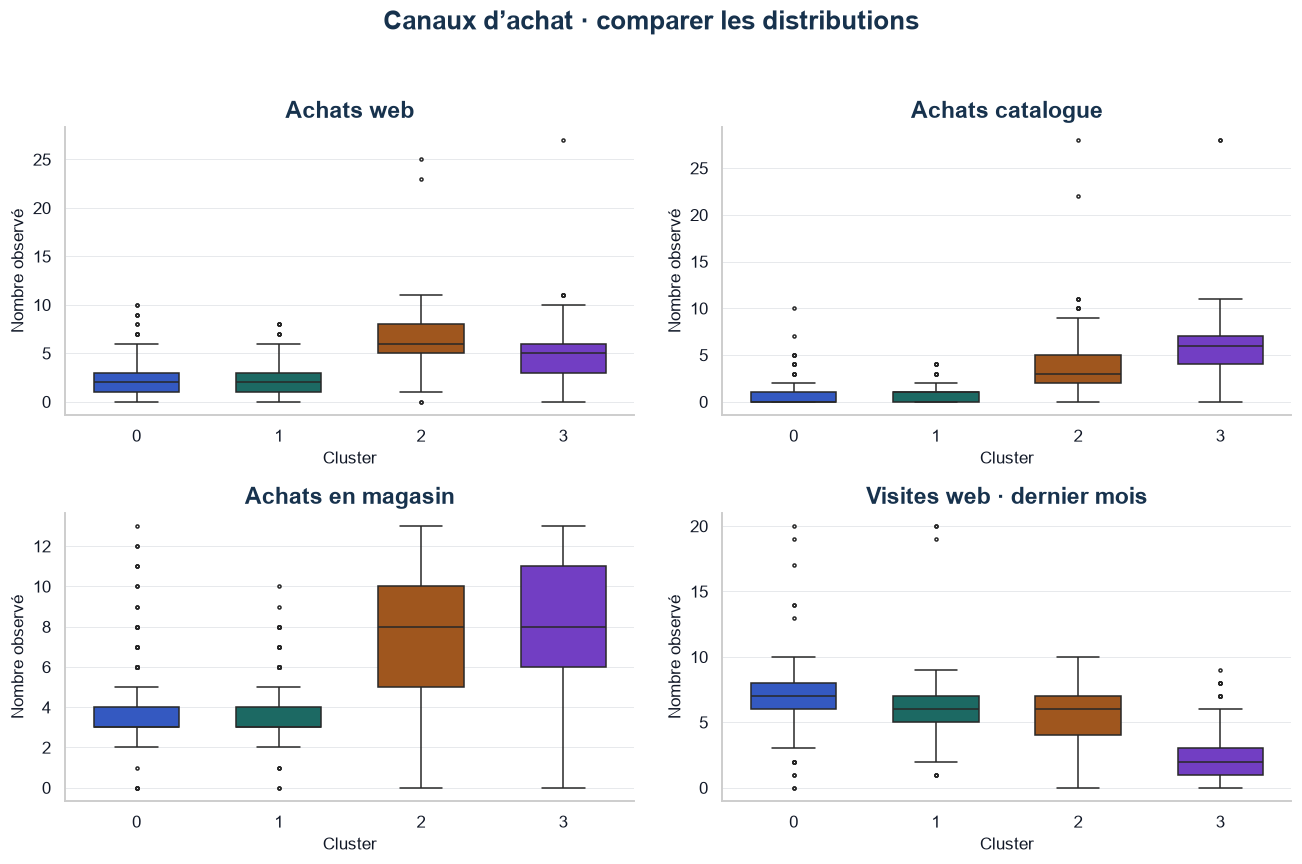

,Achats web,Achats catalogue,Achats en magasin,Visites web · dernier mois
Segment,,,,
0,"2,3","0,7","3,4","6,7"
1,"2,3","0,7","3,6","5,9"
2,"6,5","3,6","7,9","5,6"
3,"5,0","6,0","8,3","2,6"


In [32]:
lieux_achat = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth"]
libelles = ["Achats web", "Achats catalogue", "Achats en magasin", "Visites web · dernier mois"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, variable, libelle in zip(axes.flat, lieux_achat, libelles):
    sns.boxplot(data=data, x="Clusters", y=variable, hue="Clusters", palette=pal, legend=False,
                width=0.6, fliersize=2, ax=ax)
    ax.set(title=libelle, xlabel="Cluster", ylabel="Nombre observé")
fig.suptitle("Canaux d’achat · comparer les distributions", color=ENCRE, fontweight="bold", fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
franciser(fig)
plt.show()
canaux = data.groupby("Clusters")[lieux_achat].mean()
canaux.columns = libelles
canaux.index.name = "Segment"
display(tableau(canaux, precision=1))

Le cluster 3 effectue davantage d’achats par catalogue et en magasin ; le cluster 2 est actif sur le web. Les clusters 0 et 1 enregistrent davantage de visites web que d’achats web.

Les visites portent sur le dernier mois, tandis que les achats n’ont pas la même fenêtre explicitée dans le fichier. Leurs rapports ne sont donc pas interprétés comme des taux de conversion. Les canaux d’achat ont également participé au clustering.

<a id="8"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">08 · Profils des clients</h2>

Les moyennes et proportions ci-dessous décrivent les segments dans l’échantillon. Les noms des profils sont des résumés descriptifs ; ils ne prédisent pas le comportement futur de chaque client.

In [33]:
# Tableau de synthèse des profils (moyennes par cluster)
profil = data.groupby("Clusters").agg(
    Effectif=("Income", "size"),
    Revenu=("Income", "mean"),
    Depense_totale=("Spent", "mean"),
    Age=("Age", "mean"),
    Part_parents=("Is_Parent", "mean"),
    Enfants=("Kidhome", "mean"),
    Adolescents=("Teenhome", "mean"),
    Taille_foyer=("Family_Size", "mean"),
    Taille_foyer_max=("Family_Size", "max"),
    Achats_promo=("NumDealsPurchases", "mean"),
    Campagnes_acceptees=("Total_Promos", "mean"),
    Reponse_derniere_campagne=("Response", "mean"),
)
profil = profil.T.rename(index={
    "Effectif": "Effectif", "Revenu": "Revenu moyen", "Depense_totale": "Dépense totale moyenne",
    "Age": "Âge moyen", "Part_parents": "Part de parents", "Enfants": "Jeunes enfants (moyenne)",
    "Adolescents": "Adolescents (moyenne)", "Taille_foyer": "Taille moyenne du foyer",
    "Taille_foyer_max": "Taille maximale du foyer", "Achats_promo": "Achats en promotion (moyenne)",
    "Campagnes_acceptees": "Campagnes acceptées (moyenne)", "Reponse_derniere_campagne": "Réponse à la dernière campagne (taux)"})
profil.columns.name = "Segment"
display(tableau(profil, lignes={"Effectif": 0, "Revenu moyen": 0, "Dépense totale moyenne": 0,
                                "Âge moyen": 1, "Taille maximale du foyer": 0}))

Segment,0,1,2,3
Effectif,600,509,609,494
Revenu moyen,31 164,42 642,60 135,76 736
Dépense totale moyenne,130,127,833,1 404
Âge moyen,"37,5","49,3","48,2","46,2"
Part de parents,"0,73","1,00","1,00","0,05"
Jeunes enfants (moyenne),"0,72","0,78","0,24","0,01"
Adolescents (moyenne),"0,01","1,02","0,94","0,05"
Taille moyenne du foyer,"2,35","3,48","2,89","1,62"
Taille maximale du foyer,3,5,5,2
Achats en promotion (moyenne),"1,76","2,54","3,70","1,09"


**Lire les distributions.** Les variables catégorielles sont représentées par des proportions, plutôt que par des densités continues. L’âge et l’ancienneté sont comparés avec des boîtes à moustaches.

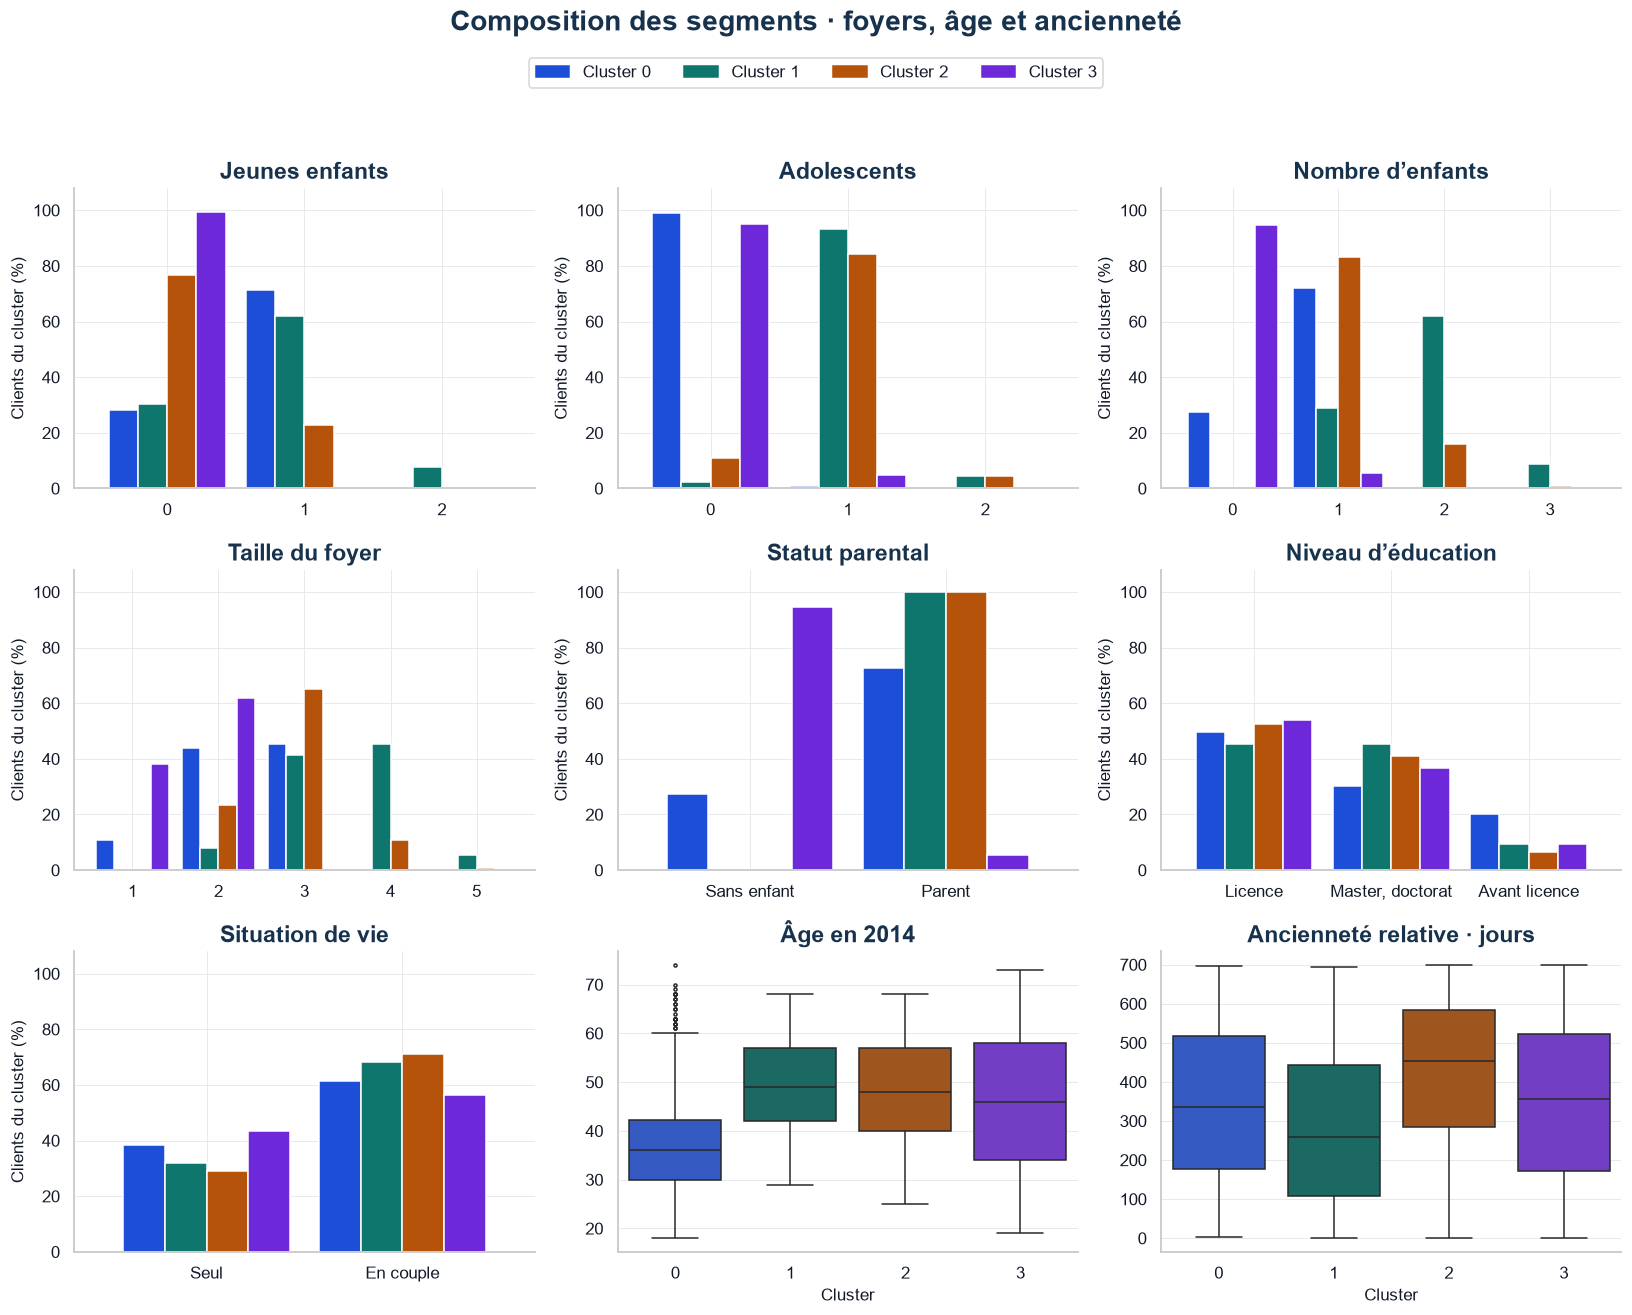

In [34]:
variables_personnelles = ["Kidhome", "Teenhome", "Children", "Family_Size", "Is_Parent", "Education", "Living_With"]
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, variable in zip(axes.flat, variables_personnelles):
    parts = pd.crosstab(data[variable], data["Clusters"], normalize="columns").mul(100)
    if variable == "Education":
        parts = parts.rename(index={0: "Licence", 1: "Master, doctorat", 2: "Avant licence"})
    elif variable == "Living_With":
        parts = parts.rename(index={0: "Seul", 1: "En couple"})
    elif variable == "Is_Parent":
        parts = parts.rename(index={0: "Sans enfant", 1: "Parent"})
    parts.plot.bar(ax=ax, color=pal, legend=False, width=0.85)
    ax.set(title=LIBELLES[variable], xlabel="", ylabel="Clients du cluster (%)", ylim=(0, 108))
    ax.tick_params(axis="x", rotation=0)
for ax, variable in zip(list(axes.flat)[7:], ["Age", "Customer_For"]):
    sns.boxplot(data=data, x="Clusters", y=variable, hue="Clusters", palette=pal, legend=False, fliersize=2, ax=ax)
    ax.set(title="Âge en 2014" if variable == "Age" else "Ancienneté relative · jours", xlabel="Cluster", ylabel="")
fig.legend(handles=[Patch(color=pal[i], label=f"Cluster {i}") for i in range(4)],
           loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.965))
fig.suptitle("Composition des segments · foyers, âge et ancienneté", color=ENCRE, fontsize=18, fontweight="bold", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.93))
franciser(fig)
plt.show()

**Synthèse descriptive des profils**

<table style="width:100%;border-collapse:collapse;background:#F3F4F6;color:#000000;font-family:Arial,sans-serif;">
<thead>
<tr>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Segment</th>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Effectif</th>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Profil observé</th>
</tr>
</thead>
<tbody>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;"><strong>0 · Jeunes foyers à faible revenu</strong></td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">600</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Âge moyen 37 ans ; revenu moyen 31 164 ; dépenses moyennes 130 ; 72,7 % de parents.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;"><strong>1 · Foyers avec enfants, faibles dépenses</strong></td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">509</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Âge moyen 49 ans ; revenu moyen 42 642 ; dépenses moyennes 127 ; 100 % de parents.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;"><strong>2 · Foyers avec enfants, dépenses intermédiaires</strong></td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">609</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Âge moyen 48 ans ; revenu moyen 60 135 ; dépenses moyennes 833 ; 99,8 % de parents ; achats en promotion plus nombreux.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;"><strong>3 · Foyers surtout sans enfant, fortes dépenses</strong></td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">494</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Âge moyen 46 ans ; revenu moyen 76 736 ; dépenses moyennes 1 404 ; 94,5 % sans enfant ; réponse positive à la dernière campagne : 30,6 %.</td>
</tr>
</tbody>
</table>


Les montants sont exprimés dans les unités monétaires du jeu de données.

<a id="9"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">09 · Enseignements, hypothèses et limites</h2>

**Résultats observés.** Quatre groupes décrivent des différences de revenu, de dépenses et de composition du foyer. Les campagnes exclues du modèle apportent un descriptif complémentaire. Le découpage reste modérément séparé et n’est pas une preuve de quatre populations naturellement distinctes.

**Hypothèses commerciales à tester**

<table style="width:100%;border-collapse:collapse;background:#F3F4F6;color:#000000;font-family:Arial,sans-serif;">
<thead>
<tr>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Segment</th>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Expérience envisageable</th>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Ce qu’il faudrait mesurer</th>
</tr>
</thead>
<tbody>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">0</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Tester des parcours ou messages web adaptés.</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Achats additionnels, avec des visites et achats mesurés sur la même période.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">1</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Comparer plusieurs offres pour les foyers avec enfants.</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Réponse et achats supplémentaires par rapport à un groupe témoin.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">2</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Comparer une offre avec remise à une offre sans remise.</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Achats additionnels et marge, avec les coûts réels de la remise.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">3</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Tester une campagne centrée sur une sélection de produits.</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Réponse, achats additionnels et marge par rapport à un groupe témoin.</td>
</tr>
</tbody>
</table>


**Limites à garder visibles**

- **Séparation modérée** : silhouette 0,304 ; deux et trois groupes ont de meilleurs indices internes. Quatre groupes ne sont pas présentés comme l’optimum statistique.
- **Choix de représentation** : quatre axes conservent 61,0 % de la variance ; le coude KMeans n’est qu’un repère pour un modèle final Ward.
- **Redondance** : les dépenses et les variables familiales sont représentées plusieurs fois. Sans les quatre variables dérivées, seuls 78,3 % des clients restent dans le même segment : c’est la principale fragilité du modèle.
- **Encodage** : l’ordre alphabétique de l’éducation n’est pas un ordre de niveau d’études. Le test avec un codage ordonné conserve 92,3 % des affectations (indice de Rand ajusté 0,81) ; un encodage adapté reste préférable pour une nouvelle version du modèle.
- **Nettoyage** : 24 revenus manquants et 4 observations atypiques sont retirés. Le biais de sélection et la sensibilité aux seuils n’ont pas été évalués.
- **Validation indépendante** : les achats promotionnels et les canaux d’achat ont servi au clustering. La stabilité sur sous-échantillons est assez bonne en médiane (0,81) mais variable (5e centile 0,67) ; aucune validation sur une nouvelle période n’est possible avec ces données.
- **Causalité** : l’exposition aux campagnes, les coûts, les marges et des groupes témoins manquent. Aucune économie ni hausse de ventes n’est établie.

La prochaine amélioration méthodologique serait de construire une représentation sans redondance, avec un encodage ordonné de l’éducation, puis d’en mesurer la stabilité comme ici. Les hypothèses commerciales demandent ensuite des données et expériences dédiées.

<a id="10"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">10 · Sources et équipe</h2>

- **Données :** [Customer Personality Analysis](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis), Akash Patel, Kaggle, licence CC0 (domaine public).
- **Démarche initiale :** [Customer Segmentation: Clustering](https://www.kaggle.com/code/karnikakapoor/customer-segmentation-clustering), Karnika Kapoor. La préparation des données et l’enchaînement ACP + clustering agglomératif s’en inspirent. L’évaluation, les tests de robustesse, l’interprétation et le profilage sont propres au projet.
- **Lecture interactive :** les deux vues HTML sont régénérées par ce notebook et publiées avec GitHub Pages. GitHub affiche une vue statique des notebooks et ne lance pas leur JavaScript.

---

**Projet de groupe** : KONE Abdoulaye · N’GUESSAN Kouamé Kan Armand Loïc · SAWADOGO Wend-yam Albert · CHEFOUET CHETSONG Ghislain Joël.  
Supervision : M. LALY · ENSEA Abidjan, Data Mining, juillet 2025.  
Contribution d’Abdoulaye KONE au projet de groupe : nettoyage et création de variables, ACP, choix des segments et rédaction de l’analyse.

**Reprise individuelle (2026)** : Abdoulaye KONE a ensuite enrichi seul le projet : exploration détaillée des variables, évaluation par silhouette et Davies-Bouldin, tests de robustesse, profils et limites réécrits, vues 3D interactives et nouvelle présentation.

**Abdoulaye KONE - analyste statisticien, diplômé de l’ENSEA Abidjan**  
[LinkedIn](https://linkedin.com/in/abdoulaye-kone) · [GitHub](https://github.com/abdoul4Kone)